# E124 · Same product twice? Linking two shops' catalogues, and what the links do to a price comparison

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: the **Abt-Buy benchmark** of the Database Group of the University of Leipzig (Köpcke, Thor and Rahm 2010; CC BY 4.0): 1,081 product listings of abt.com, 1,092 of buy.com, and the 1,097 true links between them, which no model here is allowed to see and which we use only as a test |
| **You will learn** | Record linkage as a chain of models: a **latent-class mixture** on agreement patterns, the idea of Fellegi and Sunter, fitted in PyMC · why two classes find brands and what a third class is for · a **posterior over one-to-one linkages**, sampled with Gibbs and Metropolis moves, so that a linkage is a draw and not a list · a **regression whose likelihood sums over candidate links** · and the habit this series is about: writing down, at every step, what we chose, what we rejected and what would change our mind, then showing how far the answer moves under each rejected choice |

## The question

A price analyst wants to compare two online shops, abt.com and buy.com. Both sell televisions, cameras,
cables and dishwashers, often the very same ones. The question is easy to state: how much cheaper is
Buy, and is the discount the same on a \$20 cable as on a \$2,000 television? One regression would
answer it, the price at Buy on the price at Abt, product by product.

The regression needs a column that neither catalogue has: which Abt listing is the same product as which
Buy listing. There is no shared product number. There are only names, written by two different hands:
"Samsung 46' Series 6 LCD Black Flat Panel HDTV - LN46A650" in one shop and "Samsung LN46A650 46' LCD
TV" in the other.

Deciding which records in two files describe the same thing is called record linkage. Its classic uses
link people: a census to a survey, a hospital file to a death register. Fellegi and Sunter (1969) gave
the problem its statistical form, formalising procedures that Newcombe and colleagues had proposed a
decade earlier (the history is told in Sadinle 2017): compare two records field by field, and ask
whether their pattern of agreements is more typical of records that match or of records that do not. Our
records are products, which has two advantages for a lesson. Every record can be published, and the
benchmark comes with the true links, so that each step can be tested against a truth it has not seen.
Köpcke, Thor and Rahm (2010), who assembled it, found that matching products from online shops was not
solved well by the conventional approaches of the time. It is a hard case, which is what we want.

Like E120, this notebook is about an analysis that one model cannot do. Three have to work in a chain: a
model that says which pairs of listings *agree like matches*; a model that turns those pairwise opinions
into a linkage in which each product has one partner; and the regression the links were wanted for. At
each link of the chain there are several defensible models, and the first one we try is usually wrong.

We also start with a suspicion, which the literature supports. Since Neter, Maynes and Ramanathan (1965)
it has been known that false links weaken the association measured on linked data, pulling a regression
slope toward zero, and Scheuren and Winkler (1993) and Lahiri and Larsen (2005) proposed corrections (we
take this history from Wang, Ben-David and Slawski 2020). The suspicion is that the usual shortcut,
keeping the links whose probability passes a threshold and treating them as facts, looks clean and
biases the slope toward zero, and that the cure is to sample whole linkages from their posterior and
carry them into the regression. We treat this as a hypothesis and test it. It turns out to be half
right, and the half that is wrong is the more instructive. The path looks like this.

In [1]:
import os

for name in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(name, "1")  # before NumPy: one BLAS thread per chain

import logging
import re
import sys
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import nutpie
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from numba import njit
from scipy import sparse, stats
from scipy.optimize import linear_sum_assignment
from scipy.sparse.csgraph import connected_components

from pymc_challenges import data

sys.modules.pop("jax", None)   # ArviZ's lazy JAX stub; nothing here uses JAX (see E89, E118)

RANDOM_SEED = 124
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
plt.rcParams.update({"axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9})
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)
T_START = time.time()

INK, MUTED, LIGHT, GRID = "#222222", "#8a8a8a", "#d9d9d9", "#e1e0d9"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948")
SEQ = LinearSegmentedColormap.from_list("blues", ["#fcfcfb", "#cde2fb", "#6da7ec", "#256abf", "#0d366b"])


def tidy(ax, grid="y"):
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(False)
    if grid:
        ax.grid(axis=grid, color=GRID, lw=0.6)
    ax.set_axisbelow(True)

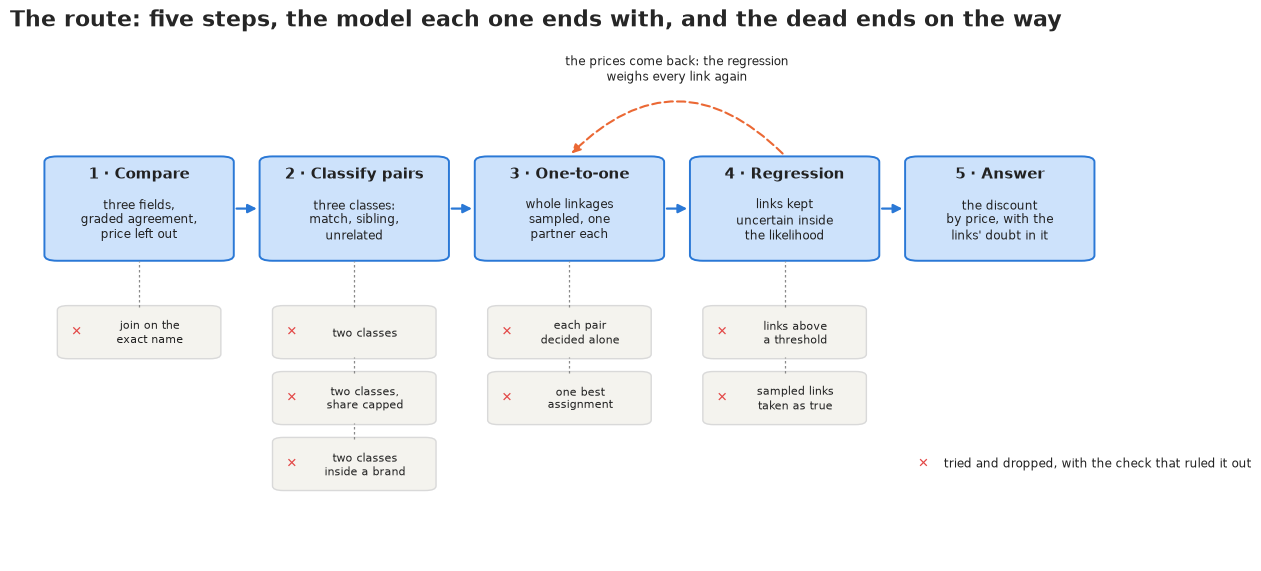

In [2]:
ROUTE = [  # step, what we end up using, what we try and drop on the way
    ("1 · Compare", "three fields,\ngraded agreement,\nprice left out", ["join on the\nexact name"]),
    ("2 · Classify pairs", "three classes:\nmatch, sibling,\nunrelated",
     ["two classes", "two classes,\nshare capped", "two classes\ninside a brand"]),
    ("3 · One-to-one", "whole linkages\nsampled, one\npartner each",
     ["each pair\ndecided alone", "one best\nassignment"]),
    ("4 · Regression", "links kept\nuncertain inside\nthe likelihood",
     ["links above\na threshold", "sampled links\ntaken as true"]),
    ("5 · Answer", "the discount\nby price, with the\nlinks' doubt in it", []),
]

fig, ax = plt.subplots(figsize=(12.5, 5.6))
for i, (step, kept, dropped) in enumerate(ROUTE):
    ax.add_patch(FancyBboxPatch((i - 0.42, 2.55), 0.84, 1.1, boxstyle="round,pad=0.02,rounding_size=0.06",
                                fc="#cde2fb", ec=BLUE, lw=1.4))
    ax.text(i, 3.47, step, ha="center", va="center", fontsize=10.5, fontweight="bold", color=INK)
    ax.text(i, 2.98, kept, ha="center", va="center", fontsize=8.6, color=INK, linespacing=1.25)
    if i < len(ROUTE) - 1:
        ax.add_patch(FancyArrowPatch((i + 0.44, 3.1), (i + 0.56, 3.1), arrowstyle="-|>", mutation_scale=13,
                                     color=BLUE, lw=1.6))
    for k, text in enumerate(dropped):
        y = 1.75 - 0.72 * k
        ax.plot([i, i], [y + 0.27, y + 0.45 if k else 2.53], color=MUTED, lw=0.9, ls=(0, (2, 2)))
        ax.add_patch(FancyBboxPatch((i - 0.36, y - 0.27), 0.72, 0.54, boxstyle="round,pad=0.02,rounding_size=0.05",
                                    fc="#f4f3ee", ec=LIGHT, lw=1.0))
        ax.text(i - 0.29, y, "✕", ha="center", va="center", fontsize=9, color=RED, fontweight="bold")
        ax.text(i + 0.05, y, text, ha="center", va="center", fontsize=8.2, color=INK, linespacing=1.2)
ax.add_patch(FancyArrowPatch((3, 3.68), (2, 3.68), connectionstyle="arc3,rad=0.5", arrowstyle="-|>",
                             mutation_scale=13, color=ORANGE, lw=1.5, ls=(0, (4, 2))))
ax.text(2.5, 4.62, "the prices come back: the regression\nweighs every link again", ha="center", va="center",
        fontsize=8.6, color=INK)
ax.text(3.62, 0.31, "✕", fontsize=9, color=RED, fontweight="bold", va="center")
ax.text(3.74, 0.31, "tried and dropped, with the check that ruled it out", fontsize=8.6, color=INK, va="center")
ax.set_xlim(-0.6, 4.6)
ax.set_ylim(-0.75, 5.0)
ax.axis("off")
ax.set_title("The route: five steps, the model each one ends with, and the dead ends on the way", loc="left");

Blue boxes are the steps and the model each one ends up with. Grey boxes are what we try first and drop,
each ruled out by a check we will show. The orange arrow is the one place where the analysis runs
backwards: the regression of step 4 sends its evidence back to the links of step 3.

Each step closes with a short box, **The choice**, that records what we kept, what we rejected and why,
and what evidence would make us choose differently. The last part reruns the answer under every
combination of the rejected choices.

| part | question | tool |
|---|---|---|
| 1 | What does it mean for two listings to agree? | three comparison fields in levels; 1.18 million pairs reduced to 39 patterns |
| 2 | Which patterns belong to matches? | latent-class mixtures in PyMC, a count that cannot be exceeded, a check on the pattern counts |
| 3 | Which listing goes with which? | a posterior over one-to-one linkages, link graphs, a test against the held-out links |
| 4 | What do the links do to the regression? | thresholds, sampled linkages, and a likelihood that keeps the links uncertain |
| 5 | How much cheaper is Buy? | the discount as a function of the price |
| 6 | Which of our choices mattered? | the slope under all 18 combinations of the choices |

## 1 · What does it mean for two listings to agree?

In [3]:
data.describe("e124_abt")
data.describe("e124_buy")
data.describe("e124_links")
abt, buy, links = data.load("e124_abt"), data.load("e124_buy"), data.load("e124_links")
N_A, N_B = len(abt), len(buy)
log_pa, log_pb = np.log(abt["price"].to_numpy()), np.log(buy["price"].to_numpy())

# The true links go in a drawer: TRUTH is used only to test, never to fit.
TRUTH = np.zeros((N_A, N_B), bool)
TRUTH[pd.Index(abt["id"]).get_indexer(links["id_abt"]), pd.Index(buy["id"]).get_indexer(links["id_buy"])] = True

print(f"\nAbt: {N_A:,} listings, {abt['price'].notna().sum()} with a price; "
      f"Buy: {N_B:,} listings, {buy['price'].notna().sum()} with a price; pairs to consider: {N_A * N_B:,}")
print(f"listings whose names are identical in the two shops: {len(abt.merge(buy, on='name'))}")
abt.head(4)

e124_abt: The 1,081 product listings of abt.com in the benchmark: id, name (the listing's title, which usually ends with a model code), price (US dollars; present for 418). The long description column of the source is dropped.
  source: Abt-Buy entity-resolution benchmark, Database Group of the University of Leipzig (Köpcke, Thor and Rahm 2010, PVLDB 3(1)), https://dbs.uni-leipzig.de/research/projects/benchmark-datasets-for-entity-resolution. Licence, as read on that page on 2026-11-14: 'These datasets are made available by the database group of Prof. Erhard Rahm under the Creative Commons license. To give proper credit please refer to this website and the VLDB2010 paper', the words 'Creative Commons license' linking to https://creativecommons.org/licenses/by/4.0/ (CC BY 4.0). DERIVED by tools/build_e124_abt_buy.py; the url is the zip archive, not this table - keep the cached file in data/ (md5 1706d855f536d0f900b5f8e5a8abd730).
  url:    https://dbs.uni-leipzig.de/files/datasets/Abt-B

,id,name,price
0,552,Sony Turntable - PSLX350H,NaN
1,580,Bose Acoustimass 5 Series III Speaker System - AM53BK,399.0
2,4696,Sony Switcher - SBV40S,49.0
3,5644,Sony 5 Disc CD Player - CDPCE375,NaN


Three tables, derived from the benchmark's archive by `tools/build_e124_abt_buy.py`: the listings of
each shop with a name and, for some, a price, and the benchmark's mapping of 1,097 true links. The
mapping goes into a drawer. `TRUTH` is used only to test, in tables and figures that say so. No model is
fitted to it, and the reasons given for each choice do not use it.

A join on the name returns 7 rows, so the naive merge is not an option. And there are 1,180,452 pairs of
listings to consider, of which at most 1,081 can be matches if each shop lists a product once: fewer
than one pair in a thousand.

The Fellegi-Sunter recipe starts by replacing each pair of records with a short vector of comparisons.
We use three, chosen by reading listings and not by trying models.

**The model code.** Most names carry one: `LN46A650`, `DVP-FX820`, `010-10723-01`. We call a token a
code if it contains a digit and has at least four characters once hyphens, dots and slashes are squeezed
out, and if it is not just a size or a resolution (`1080p`, `500gb`, `1920x1080`). Two listings then
have codes that are *identical*, that *share their first five characters*, or that are *different*. If
either listing shows no code at all, the field cannot be compared. We treat that as Sadinle (2017)
treats a missing field: it drops out of the likelihood for that pair, which assumes that whether a shop
prints the code says nothing about whether the pair is a match.

**The name.** The share of words that the two names have in common (the number of shared words over the
number of distinct words in both, the Jaccard index), cut into five levels at 0.1, 0.2, 0.3 and 0.45.

**The brand.** Whether the first word of the two names is the same.

**The price is deliberately left out.** It is what the last step studies. A link chosen because two
prices agree would hand the regression its own conclusion.

Comparing every pair sounds expensive and is not: the number of words two names share, for all pairs at
once, is one product of two sparse matrices.

In [4]:
def words(name):
    return set(re.findall(r"[a-z0-9]+", name.lower()))


NOT_A_CODE = re.compile(r"\d+(st|nd|rd|th|mm|gb|mb|w|v|p|hz|x)?|\d+x\d+")   # sizes, units, resolutions


def model_codes(name):
    """Tokens that look like a model code: a digit inside, four characters or more once - . / are squeezed."""
    out = set()
    for token in re.findall(r"[A-Za-z0-9][A-Za-z0-9\-./]*[A-Za-z0-9]", name):
        t = re.sub(r"[^a-z0-9]", "", token.lower())
        if len(t) >= 4 and re.search(r"\d", t) and not NOT_A_CODE.fullmatch(t):
            out.add(t)
    return out


def shared(sets_a, sets_b):
    """How many items each pair of records has in common: one sparse matrix product for all pairs."""
    vocab = {t: k for k, t in enumerate(sorted(set().union(*sets_a, *sets_b)))}

    def incidence(sets):
        rows = [i for i, s in enumerate(sets) for _ in s]
        cols = [vocab[t] for s in sets for t in s]
        return sparse.csr_matrix((np.ones(len(rows), np.float32), (rows, cols)), shape=(len(sets), len(vocab)))

    return (incidence(sets_a) @ incidence(sets_b).T).toarray()


words_a, words_b = [words(n) for n in abt["name"]], [words(n) for n in buy["name"]]
common = shared(words_a, words_b)
n_words_a, n_words_b = np.array([len(s) for s in words_a]), np.array([len(s) for s in words_b])
JACCARD = common / (n_words_a[:, None] + n_words_b[None, :] - common)

codes_a, codes_b = [model_codes(n) for n in abt["name"]], [model_codes(n) for n in buy["name"]]
identical = shared(codes_a, codes_b) > 0
stems_a = [{c[:5] for c in s if len(c) >= 5} for s in codes_a]
stems_b = [{c[:5] for c in s if len(c) >= 5} for s in codes_b]
similar = shared(stems_a, stems_b) > 0
has_code_a, has_code_b = np.array([len(s) > 0 for s in codes_a]), np.array([len(s) > 0 for s in codes_b])
comparable = has_code_a[:, None] & has_code_b[None, :]

first_a = np.array([re.findall(r"[a-z0-9]+", n.lower())[0] for n in abt["name"]])
first_b = np.array([re.findall(r"[a-z0-9]+", n.lower())[0] for n in buy["name"]])

LEVELS = {  # -1 means "cannot be compared"
    "code": np.where(comparable, np.where(identical, 2, np.where(similar, 1, 0)), -1),
    "name": np.digitize(JACCARD, [0.1, 0.2, 0.3, 0.45]),
    "brand": (first_a[:, None] == first_b[None, :]).astype(int),
}
FIELDS = list(LEVELS)
N_LEVELS = {"code": 3, "name": 5, "brand": 2}
LEVEL_NAMES = {"code": ["different", "same first 5", "identical"],
               "name": ["< 0.1", "0.1-0.2", "0.2-0.3", "0.3-0.45", "> 0.45"],
               "brand": ["different", "same"]}

pairs = pd.DataFrame({f: LEVELS[f].ravel() for f in FIELDS})
pat = pairs.value_counts().sort_index().rename("n").reset_index()
PID = pd.MultiIndex.from_frame(pat[FIELDS]).get_indexer(pd.MultiIndex.from_frame(pairs)).reshape(N_A, N_B)
del pairs
print(f"listings with a model code in the name: Abt {has_code_a.mean():.0%}, Buy {has_code_b.mean():.0%}")
print(f"{N_A * N_B:,} pairs fall into {len(pat)} agreement patterns; the five most common and the five rarest")
print("(code: -1 not comparable, 0 different, 1 same first five, 2 identical; name: levels 0 to 4; brand: 1 same):")
print(pd.concat([pat.sort_values("n", ascending=False).head(5), pat.sort_values("n").head(5)]).to_string(index=False))

k = int(np.where(abt["name"].str.contains("LN46A650"))[0][0])
print(f"\nAbt listing: {abt['name'][k]}\nits five nearest names in Buy, by shared words:")
for j in np.argsort(-JACCARD[k])[:5]:
    print(f"   {JACCARD[k, j]:.2f}  code {LEVEL_NAMES['code'][LEVELS['code'][k, j]]:<13} {buy['name'][j][:70]}")

listings with a model code in the name: Abt 90%, Buy 82%
1,180,452 pairs fall into 39 agreement patterns; the five most common and the five rarest
(code: -1 not comparable, 0 different, 1 same first five, 2 identical; name: levels 0 to 4; brand: 1 same):
 code  name  brand      n
    0     0      0 805757
   -1     0      0 296087
    0     0      1  37098
    0     1      0  12177
    0     1      1   9710
    0     4      0      3
    1     1      0      5
    2     0      1      6
    1     0      1      7
    1     3      0      7

Abt listing: Samsung 46' Series 6 LCD Black Flat Panel HDTV - LN46A650
its five nearest names in Buy, by shared words:
   0.36  code identical     Samsung LN46A650 46' LCD TV
   0.31  code same first 5  Samsung 9 Series LN46A950 46' LCD TV
   0.31  code different     Samsung 6 Series LN19A650 19' LCD TV
   0.31  code different     Samsung 6 Series LN32A650 32' LCD TV
   0.29  code same first 5  Samsung 7 Series LN46A750 46' LCD TV - LN46A750R1FXZA


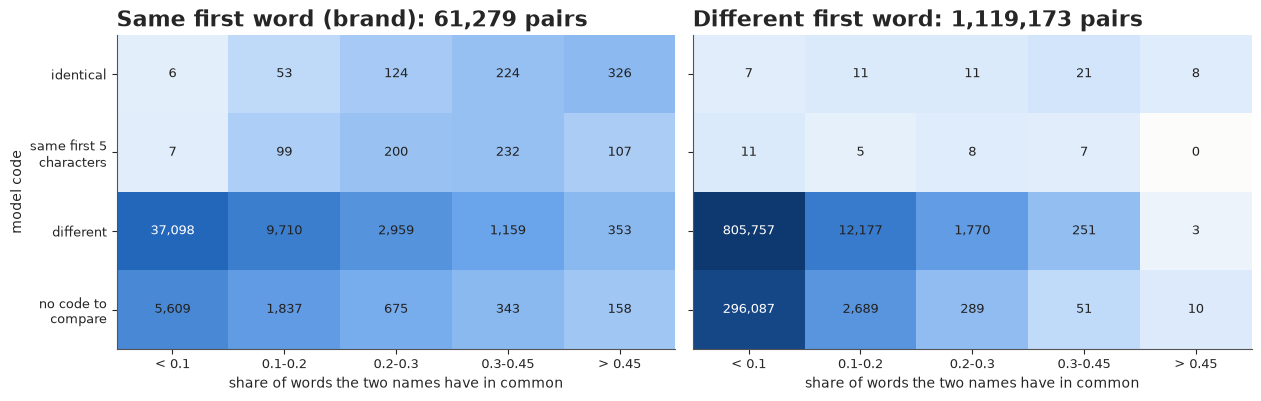

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.9), sharey=True)
code_rows = [(2, "identical"), (1, "same first 5\ncharacters"), (0, "different"), (-1, "no code to\ncompare")]
for ax, brand in zip(axes, (1, 0)):
    grid = np.zeros((4, 5))
    for r, (lev, _) in enumerate(code_rows):
        sub = pat[(pat["code"] == lev) & (pat["brand"] == brand)]
        grid[r, sub["name"].to_numpy()] = sub["n"].to_numpy()
    ax.imshow(np.log10(np.maximum(grid, 1)), cmap=SEQ, vmin=0, vmax=6, aspect="auto")
    for r in range(4):
        for c in range(5):
            ax.text(c, r, f"{int(grid[r, c]):,}", ha="center", va="center", fontsize=9,
                    color="white" if grid[r, c] > 3e4 else INK)
    ax.set_xticks(range(5), LEVEL_NAMES["name"])
    ax.set_yticks(range(4), [label for _, label in code_rows])
    ax.set_xlabel("share of words the two names have in common")
    ax.grid(False)
    ax.set_title(("Same first word (brand): " if brand else "Different first word: ")
                 + f"{int(grid.sum()):,} pairs", loc="left")
axes[0].set_ylabel("model code");

The 1.18 million pairs fall into only 39 distinct patterns, and the figure shows all of them. Almost
everything sits in the corner where nothing agrees: 805,757 pairs have different brands, different codes
and no words to speak of in common. In the opposite corner, 326 pairs share the brand, the code and many
of their words. A model of these 39 counts is a model of every pair, which is what makes the next step
cheap.

The printout shows why no single field will do. The Abt listing of the Samsung `LN46A650` finds its
partner at the top of the list with 0.36 of the words in common, and four other Samsung televisions
between 0.29 and 0.31. Two of them share the first five characters of the code. A product has siblings,
and siblings look alike.

> **The choice.** Three fields compared in levels: the model code (identical, same first five
> characters, different, or not comparable), the share of words in common (five levels) and the first
> word. *Rejected:* a join on the exact name (7 rows, where the benchmark holds 1,097 links), and the
> price as a fourth field, because the regression at the end would then be fitted to links that were
> chosen for fitting it. *Considered:* more fields, such as the descriptions that the benchmark also
> holds; every field adds parameters to each class of the next step, and three fields with graded levels
> already separate the corners of the figure. *What would change our mind:* a product number printed by
> both shops, which would make this notebook unnecessary, or evidence that the two shops write codes so
> differently that "different" stops meaning much.

## 2 · Which patterns belong to matches?

Write $\gamma_{ij}$ for the comparison vector of Abt listing $i$ and Buy listing $j$. Suppose pairs come
in two kinds, matches, a share $\lambda$ of all pairs, and non-matches, and that within a kind the
fields are independent:

$$P(\gamma) = \lambda \prod_f m_f(\gamma_f) + (1 - \lambda) \prod_f u_f(\gamma_f).$$

Here $m_f(l)$ is the probability that a match shows level $l$ in field $f$, and $u_f(l)$ the same for a
non-match. The log ratio $w(\gamma) = \sum_f \log\{m_f(\gamma_f) / u_f(\gamma_f)\}$ is the *weight* of a
pattern: positive when the pattern is more typical of matches. Fellegi and Sunter's rule sorts pairs by
this weight into links, possible links and non-links. Nobody tells us which pairs are matches, so the
$m$ and $u$ probabilities are estimated by fitting the mixture to all pairs at once, as a latent-class
model.

In PyMC the model is small. Pairs with the same pattern have the same likelihood, so the log likelihood
is a sum over 39 rows, each weighted by its number of pairs, entered with `pm.Potential`. Each class
gets a Dirichlet(2, ..., 2) prior over the levels of each field, which says only that no level is
impossible, and $\lambda$ a Beta(1, 1). The labels of a mixture are arbitrary, so every chain starts
from a rough guess in which class 0 is the one that agrees more.

### Failure 1: two classes find brands, not matches

In [6]:
DIAG = []


def diagnose(idata, label, var_names):
    s = az.summary(idata, var_names=var_names, round_to=4)
    row = {"fit": label, "divergences": int(idata.sample_stats["diverging"].sum()),
           "max r_hat": float(s["r_hat"].max()), "min ESS": float(s["ess_bulk"].min())}
    DIAG.append(row)
    print(f"{label}: {row['divergences']} divergences, max r_hat {row['max r_hat']:.2f}, "
          f"min bulk ESS {row['min ESS']:.0f}")


def start(field, role):
    """A rough first guess for a class: role 0 agrees (match), 1 half agrees (sibling), 2 disagrees."""
    lev = np.arange(N_LEVELS[field])
    if field == "brand":
        g = np.array([0.1, 0.9]) if role < 2 else np.array([0.95, 0.05])
    elif field == "code":
        g = np.array([0.2, 0.1, 0.7]) if role == 0 else np.array([0.98, 0.01, 0.01])
    else:
        g = (lev + 1.0) if role == 0 else (np.ones(len(lev)) if role == 1 else (len(lev) - lev) ** 3.0)
    return g / g.sum()


def mixture(table, fields, roles, cap=1.0, share0=0.5):
    """Latent classes of agreement patterns. Class 0 is the one we hope to read as 'match'.

    Two classes: its share is ``cap`` times a Beta(1, 1). Three classes: the shares are Dirichlet(1, 1, 1).
    Every class has a Dirichlet(2, ..., 2) prior over the levels of each field.
    """
    n = table["n"].to_numpy(float)
    K = len(roles)
    with pm.Model() as model:
        if K == 2:
            share = pm.Beta("share", 1.0, 1.0)
            w = pm.Deterministic("w", pt.stack([cap * share, 1.0 - cap * share]))
        else:
            w = pm.Dirichlet("w", np.ones(K))
        logc = pt.log(w)[:, None]
        for f in fields:
            theta = pm.Dirichlet(f"theta_{f}", 2.0 * np.ones((K, N_LEVELS[f])), shape=(K, N_LEVELS[f]))
            lev = table[f].to_numpy()
            seen = lev >= 0                                    # a field that cannot be compared drops out
            logc = logc + pt.log(theta)[:, np.where(seen, lev, 0)] * seen[None, :]
        loglik = pm.math.logsumexp(logc, axis=0)
        pm.Deterministic("p_match", pt.exp(logc[0] - loglik))
        log_m = logc[0] - pt.log(w[0])                               # log P(pattern | match)
        log_u = pm.math.logsumexp(logc[1:], axis=0) - pt.log1p(-w[0])    # log P(pattern | not a match)
        pm.Deterministic("weight", log_m - log_u)
        pm.Potential("loglik", (n * loglik).sum())
    init = {f"theta_{f}": np.stack([start(f, r) for r in roles]) for f in fields}
    init.update({"w": np.array([0.001, 0.05, 0.949])} if K == 3 else {"share": share0})
    return model, init


def expected_matches(idata, table):
    return float((idata.posterior["p_match"].mean(("chain", "draw")).to_numpy() * table["n"].to_numpy()).sum())


def class_table(idata, labels):
    rows = {}
    for f in FIELDS:
        if f"theta_{f}" in idata.posterior:
            th = idata.posterior[f"theta_{f}"].mean(("chain", "draw")).to_numpy()
            for l, name in enumerate(LEVEL_NAMES[f]):
                rows[f"{f}: {name}"] = th[:, l]
    return pd.DataFrame(rows, index=labels).T.round(3)


t0 = time.time()
model_flat, init_flat = mixture(pat, FIELDS, roles=(0, 2), share0=0.02)
with model_flat:
    idata_flat = pm.sample(random_seed=RANDOM_SEED, progressbar=False, initvals=init_flat)
diagnose(idata_flat, "two classes", ["share", "theta_code", "theta_name", "theta_brand"])
print(f"share of pairs in the class that agrees more: {float(idata_flat.posterior['share'].mean()):.4f}, "
      f"which is {expected_matches(idata_flat, pat):,.0f} pairs; most that can exist: {min(N_A, N_B):,} "
      f"({time.time() - t0:.0f} s)")
print(class_table(idata_flat, ["agrees more", "the rest"]).to_string())

two classes: 0 divergences, max r_hat 1.01, min bulk ESS 405
share of pairs in the class that agrees more: 0.0159, which is 18,717 pairs; most that can exist: 1,081 (4 s)
                    agrees more  the rest
code: different           0.907     1.000
code: same first 5        0.043     0.000
code: identical           0.050     0.000
name: < 0.1               0.009     0.985
name: 0.1-0.2             0.614     0.013
name: 0.2-0.3             0.216     0.002
name: 0.3-0.45            0.109     0.000
name: > 0.45              0.052     0.000
brand: different          0.036     0.963
brand: same               0.964     0.037


The sampler has no complaint: no divergences, r_hat 1.01. The model has converged, to something we did
not ask for. Its agreeing class holds 1.6% of the pairs, which is about 18,700 pairs, where at most
1,081 matches can exist. The table says what the class is: 96% of its pairs share the brand, most of
their names overlap a little (0.1 to 0.2), and their codes are different nine times in ten. This is not
"the same product". It is "the same brand".

A mixture finds the strongest grouping in the data, and nothing obliges that grouping to be the one we
care about. Sadinle (2017) makes the same point about this approach, and quotes Winkler's experience at
the US Census Bureau that it works when, among other conditions, matches are more than 5% of the pairs.
Ours are under 0.1%.

### Failure 2: a ceiling on the share does not change what the classes are

The obvious repair is to tell the model what we know. There are at most 1,081 matches, so $\lambda$ can
be at most 1/1,092. We write $\lambda = s / 1{,}092$, where $s$, the share of Abt listings that have a
partner, gets a Beta(1, 1) prior.

In [7]:
t0 = time.time()
model_cap, init_cap = mixture(pat, FIELDS, roles=(0, 2), cap=1.0 / N_B)
with model_cap:
    idata_cap = pm.sample(tune=1000, target_accept=0.95, random_seed=RANDOM_SEED, progressbar=False,
                          initvals=init_cap)
diagnose(idata_cap, "two classes, share capped", ["share", "theta_code", "theta_name", "theta_brand"])
print(f"share of Abt listings with a partner: {float(idata_cap.posterior['share'].mean()):.4f}; "
      f"pairs the model would call matches: {expected_matches(idata_cap, pat):,.0f}; "
      f"most that can exist: {min(N_A, N_B):,} ({time.time() - t0:.0f} s)")
print(class_table(idata_cap, ["'match' class", "the rest"]).to_string())

two classes, share capped: 0 divergences, max r_hat 1.01, min bulk ESS 350
share of Abt listings with a partner: 0.9999; pairs the model would call matches: 7,921; most that can exist: 1,081 (3 s)
                    'match' class  the rest
code: different             0.783     1.000
code: same first 5          0.100     0.000
code: identical             0.117     0.000
name: < 0.1                 0.000     0.976
name: 0.1-0.2               0.293     0.021
name: 0.2-0.3               0.353     0.003
name: 0.3-0.45              0.234     0.000
name: > 0.45                0.120     0.000
brand: different            0.008     0.954
brand: same                 0.992     0.046


The share $s$ is pinned against its ceiling, at 0.9999: the likelihood wants a bigger class than we
allow. And the ceiling does not buy what we wanted. If we ask every pair for its posterior probability
of belonging to the match class and add them up, we get about 7,900 pairs, seven times what can exist.
The class has changed from "same brand" to "same brand and a similar name" (99% share the brand; only
12% have identical codes). It is still not "same product".

The reason is the independence assumption, and it is worth a moment because it is the reason for the
next model. Among non-matches the fields are far from independent: two listings of the same brand tend
to have similar names *and* similar codes. A two-class model has one device for making fields move
together, which is the class. So it spends its match class on explaining why brand, name and code agree
together, and the pairs that do that are siblings far more often than twins.

The fix follows. Let the non-matches be of two kinds, **siblings** (related products) and **unrelated**
pairs, and ask for independence only within each kind. That is a mixture of three classes: match,
sibling, unrelated.

The standard remedy in practice is different, and we fit it too so that it can be compared: *blocking*.
Compare only listings that agree on some key, here the brand, and fit two classes inside the blocks,
with the match share capped as before.

In [8]:
t0 = time.time()
model_3, init_3 = mixture(pat, FIELDS, roles=(0, 1, 2))
with model_3:
    idata_3 = pm.sample(draws=2000, tune=1000, target_accept=0.95, random_seed=RANDOM_SEED, progressbar=False,
                        initvals=init_3)
diagnose(idata_3, "three classes", ["w", "theta_code", "theta_name", "theta_brand"])
w3 = idata_3.posterior["w"].mean(("chain", "draw")).to_numpy() * N_A * N_B
print(f"pairs per class: match {w3[0]:,.0f}, sibling {w3[1]:,.0f}, unrelated {w3[2]:,.0f}; "
      f"pairs the model would call matches: {expected_matches(idata_3, pat):,.0f} ({time.time() - t0:.0f} s)")
lam3 = idata_3.posterior["w"].isel(w_dim_0=0).to_numpy().ravel() * N_A * N_B
print(f"size of the match class, 94% interval: {np.quantile(lam3, 0.03):,.0f} to {np.quantile(lam3, 0.97):,.0f}")
print(class_table(idata_3, ["match", "sibling", "unrelated"]).to_string())

# the usual remedy, for comparison: only compare listings of the same brand, then two classes
block = pat[pat["brand"] == 1].reset_index()
model_blk, init_blk = mixture(block, ["code", "name"], roles=(0, 1), cap=min(N_A, N_B) / block["n"].sum())
with model_blk:
    idata_blk = pm.sample(tune=1000, target_accept=0.95, random_seed=RANDOM_SEED, progressbar=False,
                          initvals=init_blk)
diagnose(idata_blk, "two classes inside a brand", ["share", "theta_code", "theta_name"])
print(f"inside brand blocks: {block['n'].sum():,} pairs; "
      f"pairs the model would call matches: {expected_matches(idata_blk, block):,.0f}")

three classes: 0 divergences, max r_hat 1.00, min bulk ESS 1340
pairs per class: match 1,828, sibling 17,231, unrelated 1,161,393; pairs the model would call matches: 1,827 (8 s)
size of the match class, 94% interval: 1,565 to 2,533
                    match  sibling  unrelated
code: different     0.132    0.989      1.000
code: same first 5  0.359    0.009      0.000
code: identical     0.509    0.002      0.000
name: < 0.1         0.007    0.039      0.985
name: 0.1-0.2       0.059    0.656      0.013
name: 0.2-0.3       0.232    0.207      0.002
name: 0.3-0.45      0.363    0.078      0.000
name: > 0.45        0.338    0.020      0.000
brand: different    0.051    0.021      0.963
brand: same         0.949    0.979      0.037


two classes inside a brand: 0 divergences, max r_hat 1.01, min bulk ESS 584
inside brand blocks: 61,279 pairs; pairs the model would call matches: 1,556


patterns whose expected count is off by more than a factor of two: two classes capped 82%, three classes 5%


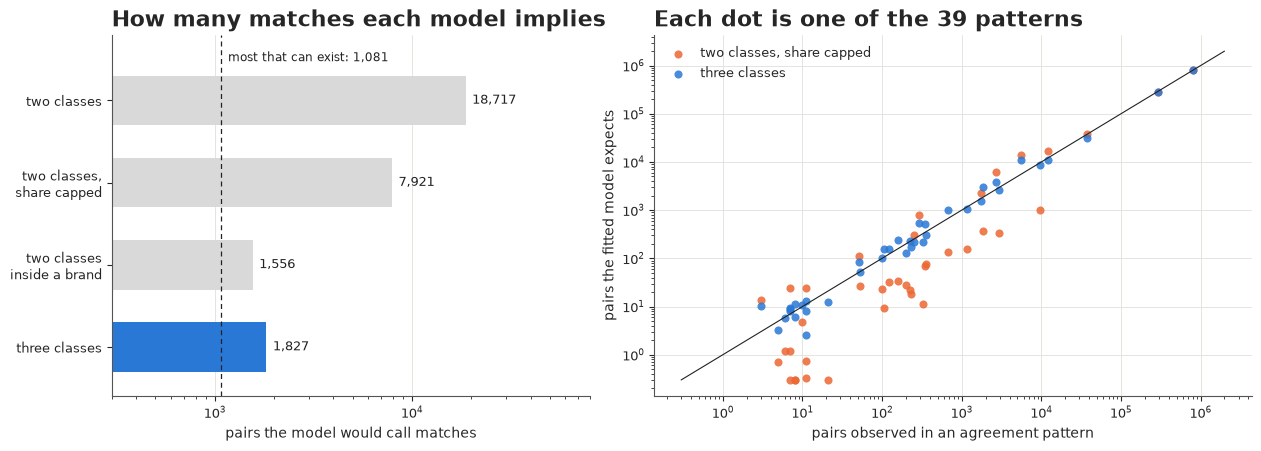

In [9]:
def pattern_fit(idata, table, fields):
    """Expected number of pairs in each pattern under the fitted classes (posterior mean)."""
    post = az.extract(idata, num_samples=300, random_seed=RANDOM_SEED)
    prob = post["w"].to_numpy()[:, None, :]                          # class, pattern, draw
    for f in fields:
        lev = table[f].to_numpy()
        th = post[f"theta_{f}"].to_numpy()[:, np.where(lev >= 0, lev, 0), :]
        prob = prob * np.where((lev >= 0)[None, :, None], th, 1.0)
    prob = prob.sum(0).mean(1)
    group = (table["code"] >= 0).to_numpy()                         # patterns with and without a code to compare
    size = np.where(group, table["n"][group].sum(), table["n"][~group].sum())
    return prob * size


fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
sizes = {"two classes": expected_matches(idata_flat, pat),
         "two classes,\nshare capped": expected_matches(idata_cap, pat),
         "two classes\ninside a brand": expected_matches(idata_blk, block),
         "three classes": expected_matches(idata_3, pat)}
ypos = np.arange(len(sizes))[::-1]
ax.barh(ypos, list(sizes.values()), color=[LIGHT, LIGHT, LIGHT, BLUE], height=0.6)
for yv, v in zip(ypos, sizes.values()):
    ax.text(v * 1.08, yv, f"{v:,.0f}", va="center", fontsize=9, color=INK)
ax.axvline(min(N_A, N_B), color=INK, lw=0.9, ls=(0, (4, 3)))
ax.text(min(N_A, N_B) * 1.08, 3.52, f"most that can exist: {min(N_A, N_B):,}", ha="left", va="center",
        fontsize=8.6, color=INK)
ax.set_xscale("log")
ax.set_xlim(300, 80000)
ax.set_ylim(-0.6, 3.8)
ax.set_yticks(ypos, list(sizes))
ax.set_xlabel("pairs the model would call matches")
ax.set_title("How many matches each model implies", loc="left")
tidy(ax, grid="x")

ax = axes[1]
exp_cap, exp_3 = pattern_fit(idata_cap, pat, FIELDS), pattern_fit(idata_3, pat, FIELDS)
obs = pat["n"].to_numpy()
ax.plot([0.3, 2e6], [0.3, 2e6], color=INK, lw=0.8)
ax.scatter(obs, np.maximum(exp_cap, 0.3), s=34, color=ORANGE, alpha=0.85, lw=0, label="two classes, share capped")
ax.scatter(obs, np.maximum(exp_3, 0.3), s=34, color=BLUE, alpha=0.85, lw=0, label="three classes")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("pairs observed in an agreement pattern")
ax.set_ylabel("pairs the fitted model expects")
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.set_title("Each dot is one of the 39 patterns", loc="left")
tidy(ax, grid="both")
miss = lambda e: float(np.mean(np.abs(np.log(np.maximum(e, 0.3) / obs)) > np.log(2)))
print(f"patterns whose expected count is off by more than a factor of two: "
      f"two classes capped {miss(exp_cap):.0%}, three classes {miss(exp_3):.0%}")

Three classes sort the pairs into 1.16 million unrelated ones, about 17,200 siblings and about 1,830
matches. The left panel puts the four models side by side: about 18,700 implied matches with two
classes, 7,900 with the share capped, 1,560 with two classes inside brand blocks and 1,830 with three
classes. The right panel is a posterior predictive check on the only data the model has, the 39 pattern
counts (an expected count below 0.3 is drawn at 0.3). The capped two-class model misses 82% of the
patterns by more than a factor of two, mostly from below: the patterns it cannot produce are the ones
where fields agree together. With three classes 5% of the patterns, two of 39, are off by that much.

The match class is the least certain part. Its size has a 94% interval from about 1,570 to 2,530 pairs.
The data cannot say much about one question, whether a pair with similar names and different codes is a
match with a miswritten code or a sibling, and the posterior is a long ridge along that question. That
ridge is why the mixtures, from the capped one onward, are given 1,000 warm-up steps and a target
acceptance of 0.95 in place of the defaults.

The next figure shows what the three classes are, and the cell after it opens the drawer for the first
time.

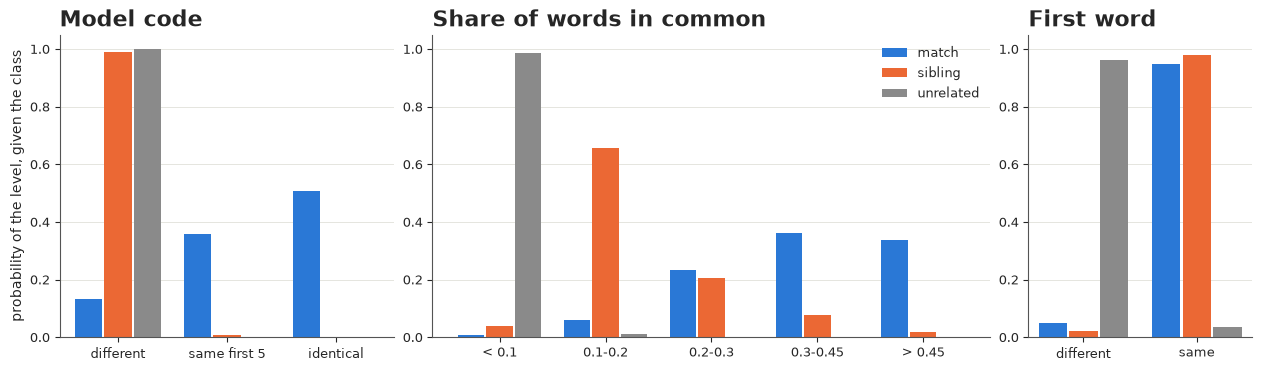

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6), gridspec_kw={"width_ratios": [3, 5, 2]})
for ax, f in zip(axes, FIELDS):
    th = idata_3.posterior[f"theta_{f}"].mean(("chain", "draw")).to_numpy()
    xs = np.arange(N_LEVELS[f])
    for kk, (label, colour) in enumerate([("match", BLUE), ("sibling", ORANGE), ("unrelated", MUTED)]):
        ax.bar(xs + (kk - 1) * 0.27, th[kk], width=0.25, color=colour, label=label)
    ax.set_xticks(xs, LEVEL_NAMES[f])
    ax.set_ylim(0, 1.05)
    ax.set_title({"code": "Model code", "name": "Share of words in common", "brand": "First word"}[f],
                 loc="left")
    tidy(ax)
axes[0].set_ylabel("probability of the level, given the class")
axes[1].legend(frameon=False, fontsize=9, loc="upper right");

In [11]:
# TEST against the held-out truth: are the pair-by-pair probabilities right?
P_PAIR = idata_3.posterior["p_match"].mean(("chain", "draw")).to_numpy()[PID]
BINS = np.array([0, 0.02, 0.1, 0.3, 0.5, 0.7, 0.9, 0.98, 1.0])


def reliability(prob, label):
    keep = prob > 0.005
    cut = pd.cut(prob[keep], BINS, include_lowest=True)
    out = pd.DataFrame({"p": prob[keep], "true": TRUTH[keep]}).groupby(cut, observed=True).agg(
        pairs=("true", "size"), mean_probability=("p", "mean"), share_true=("true", "mean"))
    out.index.name = label
    return out


def link_quality(mask):
    return int(mask.sum()), float(TRUTH[mask].mean()), float((TRUTH & mask).sum() / TRUTH.sum())


rel_pair = reliability(P_PAIR, "pair by pair")
print(rel_pair.round(3).to_string())
n_link, prec, rec = link_quality(P_PAIR > 0.5)
print(f"\nlinks with probability above 0.5: {n_link:,}; {prec:.0%} of them are true; "
      f"they find {rec:.0%} of the {TRUTH.sum():,} true links")
print(f"true links whose first words differ, which blocking on the brand would never see: "
      f"{int((TRUTH & (LEVELS['brand'] == 0)).sum())}")
print(f"Abt listings with two or more such links: {int(((P_PAIR > 0.5).sum(1) > 1).sum())}; "
      f"Buy listings: {int(((P_PAIR > 0.5).sum(0) > 1).sum())}; "
      f"largest sum of probabilities for one Abt listing: {P_PAIR.sum(1).max():.1f}")

                pairs  mean_probability  share_true
pair by pair                                       
(-0.001, 0.02]   5347             0.013       0.007
(0.02, 0.1]      1166             0.065       0.014
(0.1, 0.3]       1181             0.147       0.055
(0.3, 0.5]        350             0.324       0.180
(0.5, 0.7]        163             0.631       0.454
(0.7, 0.9]        280             0.798       0.289
(0.9, 0.98]       382             0.957       0.445
(0.98, 1.0]       686             0.994       0.827

links with probability above 0.5: 1,511; 59% of them are true; they find 81% of the 1,097 true links
true links whose first words differ, which blocking on the brand would never see: 92
Abt listings with two or more such links: 258; Buy listings: 251; largest sum of probabilities for one Abt listing: 10.9


The classes now deserve their names. A **match** has an identical code half of the time and a code with
the same first five characters a third of the time, and its names share many words. A **sibling** has
the same brand (98%), names that overlap a little, and a different code (99%). An **unrelated** pair
shares nothing.

**The test against the held-out links** is sobering all the same. Pairs to which the model gives a
probability between 0.9 and 0.98 are true matches 45% of the time, and those between 0.7 and 0.9 only
29% of the time. Taking every pair above 0.5 gives 1,511 links, of which 59% are true. And 258 Abt
listings have two or more such links; for one listing the probabilities add up to nearly eleven
partners. The model still claims about 1,830 matches for 1,081 listings.

This cannot be repaired with a fourth class. It comes from deciding every pair alone. When a television
has five siblings, each of the six look-alikes is "probably a match" taken alone, and a model of pairs
cannot know that at most one of them is.

> **The choice.** Three latent classes, match, sibling and unrelated, with independent fields inside
> each. *Rejected:* two classes (18,700 "matches": the classes are brands), and two classes with the
> match share capped at what can exist (7,900 by posterior membership, and four patterns in five missed
> by more than a factor of two). *Considered:* blocking on the brand and two classes inside the blocks.
> It implies about 1,560 matches and is a reasonable model, but the 92 true links whose first words
> differ are discarded before any model sees them. *What would change our mind:* labelled pairs. A few
> hundred pairs checked by hand would let us estimate the match class directly, and test independence
> inside it, where we can only assume it.

## 3 · Which listing goes with which?

If each shop lists a product once, a linkage is not a set of independent yes-or-no answers. It is a
*matching*: each Abt listing has one partner at Buy or none, and no Buy listing has two partners.
Sadinle (2017) makes the matching itself the parameter. Write $Z_i$ for the partner of Abt listing $i$,
or "none". Given the class probabilities, the likelihood of a matching is, up to a constant, the product
of $\exp\{w(\gamma_{i Z_i})\}$ over the linked pairs: the same weights as before, but now a Buy listing
can be claimed only once.

The prior on $Z$ is his *beta prior for bipartite matchings* (which he traces to Fortini and colleagues
and to Larsen): each listing has a partner with probability $\pi$, with $\pi \sim$ Beta(1, 1), and all
matchings with the same number of links are equally likely. His Gibbs sampler visits one listing at a
time, takes it out of the matching, and gives it a partner $j$ among those still free with probability
proportional to $\exp(w_{ij})$, or no partner with probability proportional to

$$\frac{(n_B - n)\,(n_A - n - 1 + \beta)}{n + \alpha},$$

where $n_A$ and $n_B$ are the numbers of listings in the two shops, $n$ is the number of links among the
other listings, and $\alpha = \beta = 1$.

Two things here are ours and not Sadinle's. The weights come from step 2: every sampled linkage uses a
fresh posterior draw of the three-class probabilities, with the non-match side of the weight being
siblings and unrelated pairs in their fitted proportions. The matching does not send information back to
the classes. And we add two Metropolis moves to the Gibbs update, because the first check below fails
without them: two listings exchange partners, and a partner moves to a rival listing that has none. Both
keep the number of links fixed, so the prior cancels and only the weights enter the acceptance ratio.

### Failure 3: Gibbs updates alone do not mix

In [12]:
@njit
def sweep(Z, owner, pid, ew, pl_ptr, pl_idx, cl_ptr, cl_idx, alpha, beta, u, v):
    """One pass over the Abt listings. Z[i] is the Buy partner of i or -1; owner[j] the Abt partner of j."""
    n_a, n_b = pid.shape
    n_links = (Z >= 0).sum()
    cum = np.empty(n_b)
    for i in range(n_a):                                # Gibbs: a new partner for i among the free ones, or none
        if Z[i] >= 0:
            owner[Z[i]] = -1
            n_links -= 1
            Z[i] = -1
        total = 0.0
        for j in range(n_b):
            if owner[j] < 0:
                total += ew[pid[i, j]]
            cum[j] = total
        none = (n_b - n_links) * (n_a - n_links - 1 + beta) / (n_links + alpha)
        r = u[i] * (total + none)
        if r < total:
            j = np.searchsorted(cum, r, side="right")
            Z[i] = j
            owner[j] = i
            n_links += 1
    for t in range(v.shape[0]):                         # Metropolis: i and the owner of a rival partner exchange
        for i in range(n_a):
            size = pl_ptr[i + 1] - pl_ptr[i]
            ji = Z[i]
            if size == 0 or ji < 0:
                continue
            mine = False
            for m in range(pl_ptr[i], pl_ptr[i + 1]):
                if pl_idx[m] == ji:
                    mine = True
            jk = pl_idx[pl_ptr[i] + int(v[t, i, 0] * size)]
            k = owner[jk]
            if not mine or k < 0 or k == i:
                continue
            if v[t, i, 1] * ew[pid[i, ji]] * ew[pid[k, jk]] < ew[pid[i, jk]] * ew[pid[k, ji]]:
                Z[i], Z[k] = jk, ji
                owner[jk], owner[ji] = i, k
        for j in range(n_b):                            # Metropolis: a partner j moves to a rival that has none
            size = cl_ptr[j + 1] - cl_ptr[j]
            i = owner[j]
            if size == 0 or i < 0:
                continue
            mine = False
            for m in range(cl_ptr[j], cl_ptr[j + 1]):
                if cl_idx[m] == i:
                    mine = True
            k = cl_idx[cl_ptr[j] + int(v[t, j, 2] * size)]
            if not mine or Z[k] >= 0:
                continue
            if v[t, j, 3] * ew[pid[i, j]] < ew[pid[k, j]]:
                Z[i], Z[k] = -1, j
                owner[j] = k
    return n_links


def sample_linkages(weights, pair_prob, chains=4, draws=500, thin=5, burn=50, swaps=4, seed=RANDOM_SEED,
                    alpha=1.0, beta=1.0):
    """Linkages from their posterior. ``weights``: posterior draws of the pattern weights (pattern, draw).

    Exchanges and moves are proposed among plausible partners only (pair probability above 0.05).
    """
    pl = sparse.csr_matrix(pair_prob > 0.05)
    cl = pl.tocsc()
    out = np.empty((chains, draws, N_A), np.int32)
    for c in range(chains):
        gen = np.random.default_rng([seed, c])
        order = gen.permutation(weights.shape[1])
        Z, owner = np.full(N_A, -1), np.full(N_B, -1)
        for s in range(draws):
            ew = np.exp(weights[:, order[s % len(order)]])
            for _ in range(burn if s == 0 else thin):
                sweep(Z, owner, PID, ew, pl.indptr, pl.indices, cl.indptr, cl.indices, alpha, beta,
                      gen.random(N_A), gen.random((swaps, max(N_A, N_B), 4)))
            out[c, s] = Z
    return out


def link_probability(Zs):
    flat = Zs.reshape(-1, N_A)
    P = np.zeros((N_A, N_B))
    rows = np.broadcast_to(np.arange(N_A), flat.shape)
    np.add.at(P, (rows[flat >= 0], flat[flat >= 0]), 1.0)
    return P / len(flat)


def pattern_weights(idata, table=pat, n_draws=500):
    """Posterior draws of log m/u for every pattern; a pattern outside ``table`` can never be a link."""
    w = np.full((len(pat), n_draws), -np.inf)
    rows = table["index"].to_numpy() if "index" in table else np.arange(len(pat))
    w[rows] = az.extract(idata, var_names="weight", num_samples=n_draws, random_seed=RANDOM_SEED).to_numpy()
    return w


t0 = time.time()
Z_3 = sample_linkages(pattern_weights(idata_3), P_PAIR)
P_LINK = link_probability(Z_3)
n_links = (Z_3 >= 0).sum(-1)
print(f"{Z_3.shape[0]} chains of {Z_3.shape[1]} linkages in {time.time() - t0:.0f} s; "
      f"links per linkage: {n_links.mean():,.0f} (sd {n_links.std():.0f}), "
      f"r_hat of that number {float(az.rhat(n_links)):.2f}")


def chain_spread(Zs):
    """For every possible link, the largest difference between two chains in its probability."""
    return np.ptp(np.stack([link_probability(Zs[c:c + 1]) for c in range(Zs.shape[0])]), axis=0)


spread_gibbs = chain_spread(sample_linkages(pattern_weights(idata_3), P_PAIR, swaps=0))
spread = chain_spread(Z_3)
for label, sp in (("Gibbs updates alone", spread_gibbs), ("with exchanges and moves", spread)):
    print(f"{label:<25} largest difference between two chains in a link's probability {sp.max():.2f}; "
          f"links that differ by more than 0.1: {int((sp > 0.1).sum())}, by more than 0.5: {int((sp > 0.5).sum())}")
del spread_gibbs, spread
print(f"links with probability above 0.5: {int((P_LINK > 0.5).sum()):,}; "
      f"Abt listings with two or more: {int(((P_LINK > 0.5).sum(1) > 1).sum())}")

4 chains of 500 linkages in 4 s; links per linkage: 1,055 (sd 7), r_hat of that number 1.00


Gibbs updates alone       largest difference between two chains in a link's probability 1.00; links that differ by more than 0.1: 499, by more than 0.5: 151
with exchanges and moves  largest difference between two chains in a link's probability 0.10; links that differ by more than 0.1: 0, by more than 0.5: 0
links with probability above 0.5: 955; Abt listings with two or more: 0


Samsung 46-inch televisions: 6 Abt and 6 Buy listings; links above 0.5 pair by pair 32, one partner each 6, true links 6
Sony portable DVD players, by colour: 5 Abt and 5 Buy listings; links above 0.5 pair by pair 25, one partner each 3, true links 5


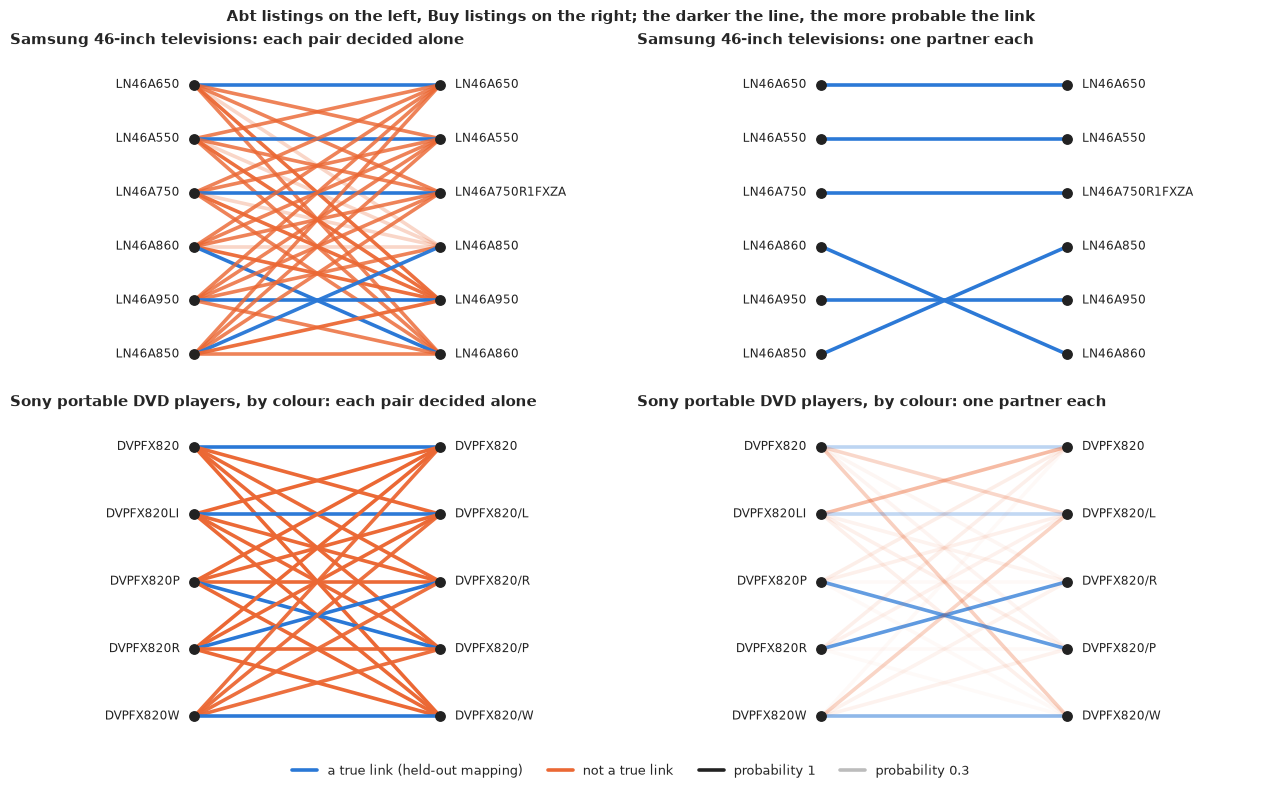

In [13]:
def short(name):
    """A label for a listing: its last model code, as written."""
    found = [t for t in re.findall(r"[A-Za-z0-9][A-Za-z0-9\-/]*[A-Za-z0-9]", name) if model_codes(t)]
    return found[-1] if found else name[:18]


def family(pattern):
    """All listings connected to the one whose name contains ``pattern`` by links that are at all plausible."""
    adj = sparse.csr_matrix((P_PAIR > 0.3) | (P_LINK > 0.05))
    _, lab = connected_components(sparse.bmat([[None, adj], [adj.T, None]]), directed=False)
    c = lab[int(np.where(abt["name"].str.contains(pattern))[0][0])]
    return np.where(lab[:N_A] == c)[0], np.where(lab[N_A:] == c)[0]


def draw_links(ax, ia, ib, prob, title):
    ya, yb = np.linspace(1, 0, len(ia)), np.linspace(1, 0, len(ib))
    for a_, i in enumerate(ia):
        for b_, j in enumerate(ib):
            if prob[i, j] > 0.01:
                ax.plot([0, 1], [ya[a_], yb[b_]], color=BLUE if TRUTH[i, j] else ORANGE,     # colour: the truth
                        alpha=float(min(prob[i, j], 1.0)), lw=2.6, solid_capstyle="round")
    ax.scatter(np.zeros(len(ia)), ya, s=46, color=INK, zorder=3)
    ax.scatter(np.ones(len(ib)), yb, s=46, color=INK, zorder=3)
    for a_, i in enumerate(ia):
        ax.text(-0.06, ya[a_], short(abt["name"][i]), ha="right", va="center", fontsize=8.6, color=INK)
    for b_, j in enumerate(ib):
        ax.text(1.06, yb[b_], short(buy["name"][j]), ha="left", va="center", fontsize=8.6, color=INK)
    ax.set_xlim(-0.75, 1.75)
    ax.set_ylim(-0.12, 1.12)
    ax.axis("off")
    ax.set_title(title, loc="left", fontsize=10.5)


# TEST against the held-out truth: the colour of a line says whether the link is true
FAMILIES = [("LN46A650", "Samsung 46-inch televisions"), ("DVPFX820LI", "Sony portable DVD players, by colour")]
fig, axes = plt.subplots(2, 2, figsize=(12.5, 7.8))
for r, (pattern, label) in enumerate(FAMILIES):
    ia, ib = family(pattern)
    draw_links(axes[r, 0], ia, ib, P_PAIR, f"{label}: each pair decided alone")
    draw_links(axes[r, 1], ia, ib, P_LINK, f"{label}: one partner each")
    sub = np.ix_(ia, ib)
    print(f"{label}: {len(ia)} Abt and {len(ib)} Buy listings; "
          f"links above 0.5 pair by pair {int((P_PAIR[sub] > 0.5).sum())}, "
          f"one partner each {int((P_LINK[sub] > 0.5).sum())}, true links {int(TRUTH[sub].sum())}")
handles = [Line2D([], [], color=BLUE, lw=2.6, label="a true link (held-out mapping)"),
           Line2D([], [], color=ORANGE, lw=2.6, label="not a true link"),
           Line2D([], [], color=INK, lw=2.6, alpha=1.0, label="probability 1"),
           Line2D([], [], color=INK, lw=2.6, alpha=0.3, label="probability 0.3")]
fig.legend(handles=handles, loc="outside lower center", ncol=4, frameon=False, fontsize=9)
fig.suptitle("Abt listings on the left, Buy listings on the right; the darker the line, the more probable the link",
             fontsize=11);

A linkage sampler needs the same check as any other sampler: do independent chains agree? With Gibbs
updates alone they do not. For 151 possible links two chains disagree by more than 0.5 in the link's
probability, and for some one chain says 1 and another 0. When two listings could each take the other's
partner, a one-at-a-time update can hardly ever swap them, because each partner is taken while the other
listing is being updated. With the exchange and move steps the four chains agree to within about 0.1 on
every link, and the number of links has an r_hat of 1.00.

A sampled linkage has about 1,055 links (sd 7), now below 1,081 by construction. 955 links have a
posterior probability above 0.5, and no listing has two of them.

The figure shows what the constraint does, for two families of products. Each panel is a small bipartite
graph: Abt listings on the left, Buy listings on the right, a line for every possible link, drawn darker
the more probable it is. Colour is the truth, revealed for the test: blue for a true link, orange for a
false one.

**The Samsung televisions** are the easy case. Six 46-inch sets in each shop, and any two of them look
like a match to a model of pairs: 32 of the 36 possible links pass 0.5. With one partner each there are
six links and all six are true. Nothing new was learned about any single pair. The listing with the
identical code claims its partner, and its siblings have nowhere left to go. Evidence about one pair has
become evidence about its rivals.

**The Sony DVD players** are the honest case. One player in five colours. For three of the colours the
links stand out. For the other two the names do not settle it: the blue player is `DVPFX820LI` in one
shop and `DVPFX820/L` in the other, the plain code `DVPFX820` appears in the names of most of the
colours, and the lines stay faint and spread out. The model knows that there are about five links here
and says that it does not know which. A list of links cannot say that; a posterior can.

a sampled linkage: 1,055 links, 89% of them true, 85% of the true links found
                              links  share true  true links found
pair by pair, above 0.5      1511.0       0.590             0.813
one partner each, above 0.5   955.0       0.982             0.855
one partner each, above 0.9   825.0       0.998             0.750
one best assignment (Jaro)   1060.0       0.919             0.888

                  pairs  mean_probability  share_true
one partner each                                     
(-0.001, 0.02]      675             0.011       0.022
(0.02, 0.1]         682             0.045       0.029
(0.1, 0.3]          322             0.181       0.193
(0.3, 0.5]          103             0.411       0.476
(0.5, 0.7]           45             0.571       0.689
(0.7, 0.9]           85             0.802       0.988
(0.9, 0.98]         112             0.956       0.982
(0.98, 1.0]         713             0.998       1.000


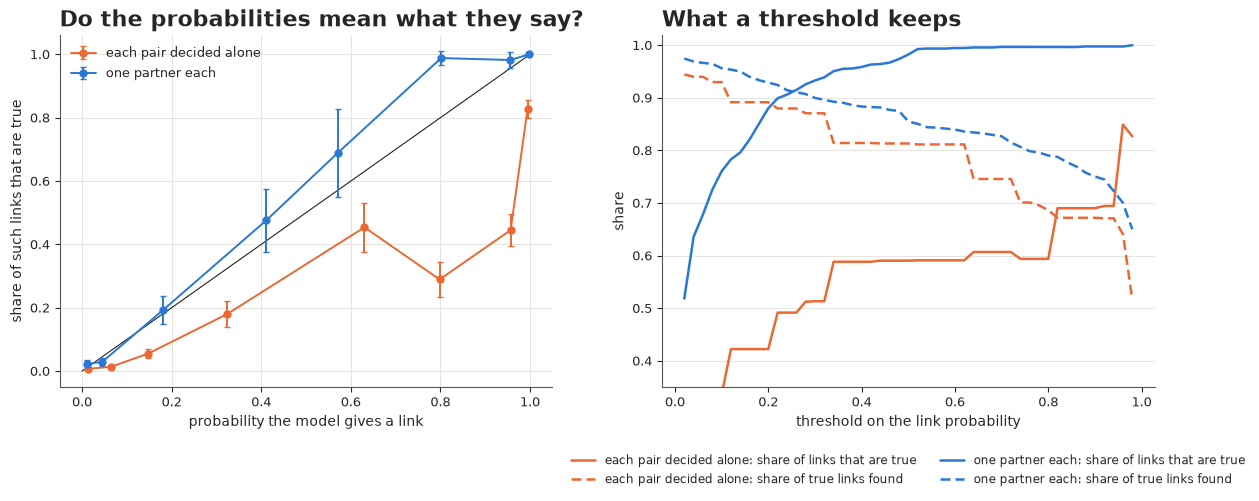

In [14]:
# TEST against the held-out truth: the linkages and their probabilities
correct = np.array([[TRUTH[np.where(z >= 0)[0], z[z >= 0]].sum() for z in chain] for chain in Z_3])
print(f"a sampled linkage: {n_links.mean():,.0f} links, {np.mean(correct / n_links):.0%} of them true, "
      f"{np.mean(correct) / TRUTH.sum():.0%} of the true links found")
quality = {"pair by pair, above 0.5": link_quality(P_PAIR > 0.5),
           "one partner each, above 0.5": link_quality(P_LINK > 0.5),
           "one partner each, above 0.9": link_quality(P_LINK > 0.9)}
W_MEAN = pattern_weights(idata_3).mean(1)[PID]
ra, rb = linear_sum_assignment(-np.maximum(W_MEAN, 0.0))
jaro = np.zeros((N_A, N_B), bool)
jaro[ra[W_MEAN[ra, rb] > 0], rb[W_MEAN[ra, rb] > 0]] = True
quality["one best assignment (Jaro)"] = link_quality(jaro)
print(pd.DataFrame(quality, index=["links", "share true", "true links found"]).T.round(3).to_string())
rel_link = reliability(P_LINK, "one partner each")
print("\n" + rel_link.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.9))
ax = axes[0]
ax.plot([0, 1], [0, 1], color=INK, lw=0.8)
for rel, colour, label in ((rel_pair, ORANGE, "each pair decided alone"), (rel_link, BLUE, "one partner each")):
    se = np.sqrt(rel["share_true"] * (1 - rel["share_true"]) / rel["pairs"])
    ax.errorbar(rel["mean_probability"], rel["share_true"], yerr=2 * se, color=colour, marker="o", ms=5, lw=1.4,
                capsize=2, label=label)
ax.set_xlabel("probability the model gives a link")
ax.set_ylabel("share of such links that are true")
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.set_title("Do the probabilities mean what they say?", loc="left")
tidy(ax, grid="both")
ax = axes[1]
taus = np.linspace(0.02, 0.98, 49)
for prob, colour, label in ((P_PAIR, ORANGE, "each pair decided alone"), (P_LINK, BLUE, "one partner each")):
    q = np.array([link_quality(prob > t) for t in taus])
    ax.plot(taus, q[:, 1], color=colour, lw=1.8, label=f"{label}: share of links that are true")
    ax.plot(taus, q[:, 2], color=colour, lw=1.8, ls=(0, (4, 2)), label=f"{label}: share of true links found")
ax.set_xlabel("threshold on the link probability")
ax.set_ylabel("share")
ax.set_ylim(0.35, 1.02)
ax.legend(frameon=False, fontsize=8.6, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
ax.set_title("What a threshold keeps", loc="left")
tidy(ax);

**Against the held-out links** the constraint is worth a great deal. A single sampled linkage has 89% of
its links right and finds 85% of the true ones. Of the 955 links with probability above 0.5, 98% are
true, against 59% of the 1,511 that the pair-by-pair model passed, and they find 85% of the true links
against 81%. The left panel shows why the probabilities can now be used as probabilities: the blue
points are close to the diagonal up to 0.5 and, above it, on the cautious side (links given 0.7 to 0.9
are true 99% of the time), while the orange points are far below the line. The threshold of one half is
not arbitrary here: under a loss that counts wrong entries of the linkage, linking $i$ and $j$ when the
posterior probability exceeds 1/2 is the Bayes estimate (a result of Tancredi and Liseo that Sadinle
2017 extends).

One rival does well on this test. The single best assignment, found by solving a linear sum assignment
problem on the mean weights as Jaro (1989) proposed, has 1,060 links of which 92% are true, and finds
89% of the true ones. It is a better list than any one posterior draw, as a mode usually is. It comes
without probabilities, and the next step needs them.

> **The choice.** A posterior over one-to-one linkages, sampled by Gibbs updates with exchange and move
> steps, with weights from step 2 that change from draw to draw. *Rejected:* deciding each pair alone
> (1,511 links above 0.5 for 1,081 listings, 59% of them true), and Gibbs updates alone (chains that
> contradict each other on 151 links). *Considered:* the single best assignment, a good list with no
> measure of doubt, and Sadinle's full sampler, which re-estimates the $m$ and $u$ probabilities from
> the matching with two classes instead of taking them from step 2. *What would change our mind:*
> duplicates inside a shop. The benchmark's mapping has 16 Abt and 5 Buy listings that appear in two
> links. Each of them is a true link that a one-to-one model must lose. At 2% of the links we accept
> that; at 20% we would need a model in which a product can have several listings.

## 4 · What do the links do to the regression?

The analyst's model is a straight line on the log scale, centred at \$100:

$$\log p^{\text{Buy}} = a + \log p^{\text{Abt}} + (b - 1)\,(\log p^{\text{Abt}} - \log 100) + \varepsilon, \qquad \varepsilon \sim \mathcal{N}(0, \sigma).$$

$a$ is the log price ratio for a product that costs \$100 at Abt, and $b$ is the slope of log price on
log price. If $b = 1$ Buy's discount is the same percentage at every price. If $b > 1$ the discount
shrinks as products get dearer. The priors are wide: $a \sim \mathcal{N}(0, 1)$ lets Buy's price at
\$100 be anything from about a third of Abt's to three times as much within one standard deviation, $b
\sim \mathcal{N}(1, 0.5)$, $\sigma \sim$ HalfNormal(0.5).

Only some listings have a price: 418 at Abt and 590 at Buy. The linkage used all listings; the
regression can use only pairs in which both are priced.

This regression will be fitted a few hundred times below, to one set of links after another, so we
compile it once with nutpie and refill it with data. Its likelihood is written in a slightly general
form whose point becomes clear later: each row is an Abt price with one or more *candidate* partners. A
link taken as certain is a row with a single candidate.

First the reference: the regression on the true links, which no step of the linkage has seen.

In [15]:
# The price regression, and as TEST material its fit to the true links (at the end of the cell)
X0 = np.log(100.0)                                  # prices are compared at 100 dollars
G_MEAN, G_SD = np.nanmean(log_pb), np.nanstd(log_pb)
PRICED = ~np.isnan(log_pa)[:, None] & ~np.isnan(log_pb)[None, :]


COMPILED = {}


def price_model(n_rows, n_cand):
    """Regression of the Buy price on the Abt price in which every row may have several candidate partners.

    Row i: an Abt price x[i], candidate Buy prices y[i, k] with link probabilities exp(logq[i, k]), and the
    probability exp(logq0[i]) that none of them is its partner. A certain link is a row with one candidate.
    Compiled once for each size and then refilled with data.
    """
    n_rows = next(size for size in (300, 600, 1600, 5000, 20000) if size >= n_rows)
    if (n_rows, n_cand) not in COMPILED:
        with pm.Model() as model:
            x = pm.Data("x", np.zeros(n_rows))
            y = pm.Data("y", np.zeros((n_rows, n_cand)))
            logq = pm.Data("logq", np.zeros((n_rows, n_cand)))
            logq0 = pm.Data("logq0", np.zeros(n_rows))
            a = pm.Normal("a", 0.0, 1.0)
            b = pm.Normal("b", 1.0, 0.5)
            sigma = pm.HalfNormal("sigma", 0.5)
            mu = a + x + (b - 1.0) * (x - X0)
            ratio = pm.logp(pm.Normal.dist(mu[:, None], sigma), y) - pm.logp(pm.Normal.dist(G_MEAN, G_SD), y)
            terms = pt.concatenate([logq0[:, None], logq + ratio], axis=1)      # no partner, or candidate k
            pm.Potential("loglik", pm.math.logsumexp(terms, axis=1).sum())
        COMPILED[n_rows, n_cand] = nutpie.compile_pymc_model(model)
    return COMPILED[n_rows, n_cand], n_rows


def fit_prices(x, y, q, q0, seed=0, draws=1000, tune=500):
    """Fill the compiled model with one data set (padded to its size) and sample."""
    n, n_cand = y.shape
    model, n_rows = price_model(n, n_cand)
    xs, ys = np.full(n_rows, X0), np.full((n_rows, n_cand), G_MEAN)
    lq, lq0 = np.full((n_rows, n_cand), -700.0), np.zeros(n_rows)          # padding: a row that says nothing
    xs[:n], ys[:n] = x, np.where(q > 0, y, G_MEAN)
    lq[:n] = np.log(np.maximum(q, 1e-300))
    lq0[:n] = np.log(np.maximum(q0, 1e-300))
    return nutpie.sample(model.with_data(x=xs, y=ys, logq=lq, logq0=lq0), draws=draws, tune=tune, chains=4,
                         seed=seed, progress_bar=False)


def certain(mask):
    """Rows for links taken as certain: every priced pair in ``mask``."""
    i, j = np.where(mask & PRICED)
    return log_pa[i], log_pb[j][:, None], np.ones((len(i), 1)), np.zeros(len(i))


def draws_of(trace):
    return {v: trace.posterior[v].to_numpy().ravel() for v in ("a", "b", "sigma")}


def worst_rhat(trace):
    return max(float(az.rhat(trace.posterior[v].to_numpy())) for v in ("a", "b", "sigma"))


def describe(d, label):
    lo, hi = np.quantile(d["b"], [0.03, 0.97])
    print(f"{label:<42} slope b {d['b'].mean():.3f} [{lo:.3f}, {hi:.3f}]   "
          f"log ratio at $100 a {d['a'].mean():+.3f} ({np.exp(d['a'].mean()) - 1:+.0%})   "
          f"sigma {d['sigma'].mean():.3f}")


# TEST material: the regression on the true links, which no step of the linkage has seen
trace_true = fit_prices(*certain(TRUTH), seed=RANDOM_SEED)
diagnose(trace_true, "regression on the true links", ["a", "b", "sigma"])
ORACLE = draws_of(trace_true)
print(f"true links with a price in both shops: {int((TRUTH & PRICED).sum())}")
describe(ORACLE, "true links (held out)")
print(f"probability that b is above 1: {(ORACLE['b'] > 1).mean():.3f}")

regression on the true links: 0 divergences, max r_hat 1.00, min bulk ESS 5858
true links with a price in both shops: 226
true links (held out)                      slope b 1.052 [1.030, 1.074]   log ratio at $100 a -0.243 (-22%)   sigma 0.242
probability that b is above 1: 1.000


On the 226 true links that are priced in both shops, Buy is 22% cheaper than Abt on a \$100 product, and
the slope is 1.05, with a 94% interval from 1.03 to 1.07. The discount shrinks as the price rises, and
the data leave no doubt about the direction: the probability that $b > 1$ is 1.000. That is the finding
a linkage must not destroy.

Now the suspicion from the introduction. A false link pairs the Abt price of one product with the Buy
price of another. That adds noise which has nothing to do with $x$, and the slope falls toward zero. So:

1. keeping the links above a threshold and taking them as true *looks clean and biases the slope toward
   zero*;
2. the cure is to drop the threshold, sample whole linkages from their posterior, fit the regression to
   each, and pool the posteriors, so that the doubt about the links is carried into the answer.

We test both. For thresholds from 0.1 to 0.99 we take the links above the threshold, once from the
pair-by-pair probabilities of step 2 and once from the one-to-one probabilities of step 3, and fit the
regression. Then we fit it to each of 100 linkages sampled in step 3 and pool the 100 posteriors.

In [16]:
# The estimates use no truth; the column "share true" is a TEST against the held-out links
t0 = time.time()
TAUS = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99])
by_tau, worst = {}, 1.0
for label, prob in (("each pair decided alone", P_PAIR), ("one partner each", P_LINK)):
    rows = []
    for tau in TAUS:
        mask = prob > tau
        tr = fit_prices(*certain(mask), seed=RANDOM_SEED, draws=500)
        worst = max(worst, worst_rhat(tr))
        d = draws_of(tr)
        rows.append({"threshold": tau, "priced links": int((mask & PRICED).sum()),
                     "share true": TRUTH[mask & PRICED].mean(), "b": d["b"].mean(),
                     "lo": np.quantile(d["b"], 0.03), "hi": np.quantile(d["b"], 0.97), "a": d["a"].mean(),
                     "sigma": d["sigma"].mean()})
    by_tau[label] = pd.DataFrame(rows)
    print(label)
    print(by_tau[label].round(3).to_string(index=False))

# linkages sampled from their posterior, each one taken as true, the posteriors pooled
flat_Z = Z_3.reshape(-1, N_A)[rng.choice(Z_3.shape[0] * Z_3.shape[1], 100, replace=False)]
pooled, share_true, n_div = [], [], 0
for s, z in enumerate(flat_Z):
    mask = np.zeros((N_A, N_B), bool)
    mask[np.where(z >= 0)[0], z[z >= 0]] = True
    tr = fit_prices(*certain(mask), seed=s, draws=250, tune=300)
    worst = max(worst, worst_rhat(tr))
    n_div += int(tr.sample_stats["diverging"].sum())
    pooled.append(draws_of(tr))
    share_true.append(TRUTH[mask & PRICED].mean())
SAMPLED = {v: np.concatenate([d[v] for d in pooled]) for v in ("a", "b", "sigma")}
DIAG.append({"fit": "regressions on thresholded and sampled links (122 fits)", "divergences": n_div,
             "max r_hat": worst, "min ESS": np.nan})
print(f"\n122 regressions in {time.time() - t0:.0f} s; worst r_hat {worst:.3f}; "
      f"divergences in the sampled-linkage fits {n_div}")
describe(ORACLE, "true links (held out)")
describe(SAMPLED, "100 sampled linkages, each taken as true")
slopes = np.array([d["b"].mean() for d in pooled])
print(f"share of the priced links in a sampled linkage that are true: {np.mean(share_true):.0%}; "
      f"slope of single linkages from {slopes.min():.3f} to {slopes.max():.3f}; "
      f"share of them below the truth's {ORACLE['b'].mean():.3f}: {(slopes < ORACLE['b'].mean()).mean():.0%}")

each pair decided alone
 threshold  priced links  share true     b    lo    hi      a  sigma
      0.10           461       0.438 0.887 0.835 0.941 -0.151  0.732
      0.20           387       0.506 0.991 0.954 1.028 -0.206  0.489
      0.30           298       0.651 1.025 0.987 1.062 -0.220  0.459
      0.40           269       0.706 1.017 0.981 1.051 -0.208  0.403
      0.50           267       0.712 1.021 0.985 1.054 -0.214  0.401
      0.60           265       0.713 1.021 0.987 1.056 -0.215  0.401
      0.70           234       0.726 1.010 0.977 1.045 -0.202  0.380
      0.80           219       0.717 1.008 0.972 1.044 -0.194  0.379
      0.90           198       0.783 1.001 0.965 1.036 -0.179  0.365
      0.95           163       0.914 1.028 0.995 1.060 -0.190  0.305
      0.99           113       0.965 1.034 0.997 1.070 -0.200  0.270


one partner each
 threshold  priced links  share true     b    lo    hi      a  sigma
      0.10           271       0.793 0.981 0.938 1.023 -0.158  0.502
      0.20           244       0.865 1.026 0.999 1.051 -0.219  0.307
      0.30           219       0.941 1.031 1.007 1.057 -0.223  0.280
      0.40           209       0.971 1.042 1.016 1.067 -0.221  0.257
      0.50           200       0.990 1.038 1.015 1.062 -0.225  0.242
      0.60           197       0.995 1.038 1.015 1.061 -0.224  0.243
      0.70           196       0.995 1.038 1.014 1.062 -0.223  0.243
      0.80           188       0.995 1.038 1.013 1.063 -0.224  0.247
      0.90           182       0.995 1.037 1.012 1.064 -0.226  0.249
      0.95           177       0.994 1.039 1.013 1.065 -0.227  0.252
      0.99           159       1.000 1.044 1.017 1.070 -0.234  0.243



122 regressions in 7 s; worst r_hat 1.036; divergences in the sampled-linkage fits 0
true links (held out)                      slope b 1.052 [1.030, 1.074]   log ratio at $100 a -0.243 (-22%)   sigma 0.242
100 sampled linkages, each taken as true   slope b 1.021 [0.977, 1.059]   log ratio at $100 a -0.209 (-19%)   sigma 0.353
share of the priced links in a sampled linkage that are true: 92%; slope of single linkages from 0.968 to 1.050; share of them below the truth's 1.052: 100%


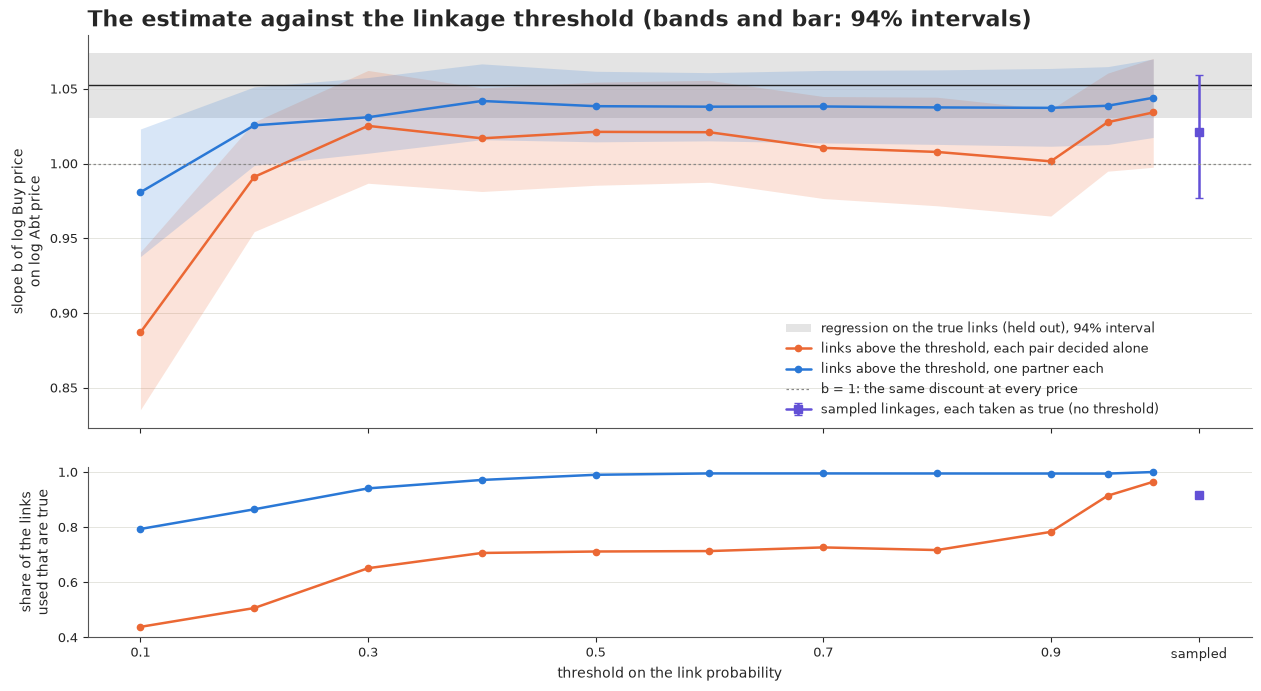

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(12.5, 6.8), sharex=True,
                         gridspec_kw={"height_ratios": [2.3, 1], "hspace": 0.1})
ax = axes[0]
lo, hi = np.quantile(ORACLE["b"], [0.03, 0.97])
ax.axhspan(lo, hi, color=LIGHT, alpha=0.7, lw=0,
           label="regression on the true links (held out), 94% interval")
ax.axhline(ORACLE["b"].mean(), color=INK, lw=1.0)
for (label, tab), colour in zip(by_tau.items(), (ORANGE, BLUE)):
    ax.fill_between(tab["threshold"], tab["lo"], tab["hi"], color=colour, alpha=0.18, lw=0)
    ax.plot(tab["threshold"], tab["b"], color=colour, marker="o", ms=4.5, lw=1.8,
            label=f"links above the threshold, {label}")
lo_s, hi_s = np.quantile(SAMPLED["b"], [0.03, 0.97])
mean_s = SAMPLED["b"].mean()
ax.errorbar([1.03], [mean_s], yerr=[[mean_s - lo_s], [hi_s - mean_s]], color=VIOLET, marker="s", ms=6, lw=1.8,
            capsize=3, label="sampled linkages, each taken as true (no threshold)")
ax.axhline(1.0, color=MUTED, lw=0.9, ls=(0, (2, 2)), label="b = 1: the same discount at every price")
ax.set_ylabel("slope b of log Buy price\non log Abt price")
ax.legend(frameon=False, fontsize=9, loc="lower right", bbox_to_anchor=(0.93, 0.0))
ax.set_title("The estimate against the linkage threshold (bands and bar: 94% intervals)", loc="left")
tidy(ax)
ax = axes[1]
for (label, tab), colour in zip(by_tau.items(), (ORANGE, BLUE)):
    ax.plot(tab["threshold"], tab["share true"], color=colour, marker="o", ms=4.5, lw=1.8)
ax.plot([1.03], [np.mean(share_true)], color=VIOLET, marker="s", ms=6)
ax.set_ylabel("share of the links\nused that are true")
ax.set_xlabel("threshold on the link probability")
ax.set_xticks([0.1, 0.3, 0.5, 0.7, 0.9, 1.03], ["0.1", "0.3", "0.5", "0.7", "0.9", "sampled"])
ax.set_ylim(0.4, 1.02)
tidy(ax);

This is the figure the question was asked for: the estimate against the linkage threshold, with the
share of true links underneath.

**Orange: links from pairs decided alone.** Here the first half of the suspicion holds. At thresholds
from 0.5 to 0.9 the slope is between 1.00 and 1.02 where the truth is 1.05, and its interval includes 1:
this analyst cannot say whether the discount shrinks with the price. But these links do not look clean.
Between 71% and 78% of them are true, and a stricter threshold makes the estimate worse before it makes
it better (1.00 at 0.9, lower than at 0.5), because the siblings with look-alike codes hold
probabilities above 0.9 and leave only at 0.95.

**Blue: links from the one-to-one posterior.** From a threshold of 0.4 upward at least 97% of the links
used are true, the slope is 1.04, and it does not move with the threshold. The interval, about 1.01 to
1.06, is clear of 1. The small gap that remains is not attenuation: at 0.99 every link used is true and
the slope is still 1.044. The confident links are a subset of the true ones, 159 of 226, and a subset
has a slope of its own. Once the links are good, the hard threshold does no visible harm.

**Violet: sampled linkages, each taken as true.** This is the cure the suspicion proposed, and it does
worse than any threshold from 0.2 upward on the very probabilities it was sampled from: 1.02, with an
interval from 0.98 to 1.06 that includes 1. Every one of the 100 sampled linkages gives a slope below
the truth's.

The reason is simple once seen. A sampled linkage is a complete linkage. It includes a link of
probability 0.3 three times in ten, and 8% of its priced links are false. A threshold at 0.5 throws the
doubtful links out; sampling keeps them in proportion to the doubt, and then the regression treats them
as facts. Pooling over linkages averages over *which* links are wrong. It cannot average the bias away,
because every false link pushes the same way.

So the suspicion named the right disease and the wrong patient. Thresholds on bad probabilities bias the
slope toward zero; thresholds on good probabilities hardly do; and "carry the sampled linkages into the
regression" carries the false links in with them. The next figure looks at one sampled linkage.

this linkage: 214 priced links, 20 of them false; sd of log price ratio: true links 0.24, false links 0.85


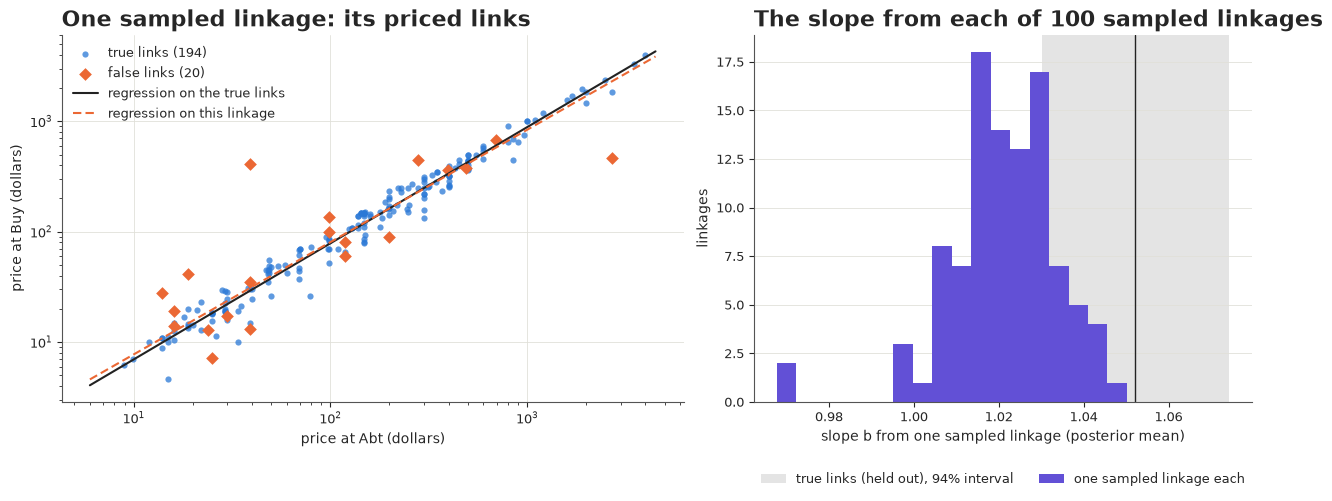

In [18]:
# TEST against the held-out truth: which links of one sampled linkage are false
z = flat_Z[0]
i_s, j_s = np.where(z >= 0)[0], z[z >= 0]
keep = PRICED[i_s, j_s]
i_s, j_s = i_s[keep], j_s[keep]
is_true = TRUTH[i_s, j_s]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.9), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
ax.scatter(np.exp(log_pa[i_s][is_true]), np.exp(log_pb[j_s][is_true]), s=20, color=BLUE, alpha=0.75, lw=0,
           label=f"true links ({is_true.sum()})")
ax.scatter(np.exp(log_pa[i_s][~is_true]), np.exp(log_pb[j_s][~is_true]), s=42, color=ORANGE, marker="D", lw=0,
           label=f"false links ({(~is_true).sum()})")
grid_x = np.linspace(np.log(6), np.log(4500), 50)
for d, colour, ls, label in ((ORACLE, INK, "-", "regression on the true links"),
                             (pooled[0], ORANGE, (0, (4, 2)), "regression on this linkage")):
    line = d["a"].mean() + grid_x + (d["b"].mean() - 1) * (grid_x - X0)
    ax.plot(np.exp(grid_x), np.exp(line), color=colour, lw=1.5, ls=ls, label=label)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("price at Abt (dollars)")
ax.set_ylabel("price at Buy (dollars)")
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.set_title("One sampled linkage: its priced links", loc="left")
tidy(ax, grid="both")
ax = axes[1]
ax.axvspan(*np.quantile(ORACLE["b"], [0.03, 0.97]), color=LIGHT, alpha=0.7, lw=0, zorder=0,
           label="true links (held out), 94% interval")
ax.axvline(ORACLE["b"].mean(), color=INK, lw=1.0, zorder=1)
ax.hist(slopes, bins=18, color=VIOLET, zorder=2, label="one sampled linkage each")
ax.set_xlabel("slope b from one sampled linkage (posterior mean)")
ax.set_ylabel("linkages")
ax.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=2)
ax.set_title("The slope from each of 100 sampled linkages", loc="left")
tidy(ax)
res_all = log_pb[j_s] - log_pa[i_s]
print(f"this linkage: {len(i_s)} priced links, {(~is_true).sum()} of them false; "
      f"sd of log price ratio: true links {res_all[is_true].std():.2f}, false links {res_all[~is_true].std():.2f}")

In this one linkage 20 of the 214 priced links are false. The true links hug the line, with a standard
deviation of 0.24 in the log price ratio. The false ones scatter around it with 0.85. They are not wild,
since a false partner is usually a sibling and siblings cost roughly the same, but they are wide enough
to flatten the line. The right panel is the whole distribution: the slope from each of the 100 linkages,
all to the left of the truth.

### The repair: put the doubt inside the likelihood

What went wrong is the division of labour. Step 3 knows which links are doubtful and knows nothing about
prices. The regression knows prices and was told that the links are facts. The repair is to tell the
regression what step 3 knows.

Take a priced Abt listing $i$. Step 3 gives it candidate partners $j$ with probabilities $q_{ij}$, and a
probability $q_{i0}$ that none of the priced Buy listings is its partner. If $j$ is the partner, its log
price $y_j$ follows the regression. If it is not, $y_j$ is just some Buy price, with density $g(y_j)$,
for which we take a normal fitted to all Buy log prices. Summing over which candidate, if any, is the
partner, and dividing by the constant $\prod_j g(y_j)$, the likelihood of listing $i$ is

$$L_i(a, b, \sigma) = q_{i0} + \sum_j q_{ij}\, \frac{\mathcal{N}(y_j \mid \mu_i, \sigma)}{g(y_j)}, \qquad \mu_i = a + x_i + (b - 1)(x_i - \log 100).$$

No link is taken as a fact, and there is no threshold. A candidate whose price is far from the line
contributes almost nothing, however probable the names made it, and one that sits on the line counts for
more than its share. The formula treats the listings one at a time, using step 3's probabilities for
each; it ignores that two listings cannot take the same partner, which step 3 has already accounted for
in those probabilities. In PyMC this is the model compiled above, with several candidates per row.

In [19]:
def candidates(P, min_q):
    """Rows for links kept uncertain: each priced Abt listing with its priced candidates and their probabilities."""
    ia, jb = np.where(~np.isnan(log_pa))[0], np.where(~np.isnan(log_pb))[0]
    Q = P[np.ix_(ia, jb)]
    k = int((Q > 0).sum(1).max())
    order = np.argsort(-Q, axis=1)[:, :k]
    q = np.take_along_axis(Q, order, 1)
    keep = q.sum(1) > 0
    q0 = np.maximum(1.0 - q.sum(1), min_q)
    return log_pa[ia][keep], log_pb[jb][order][keep], q[keep], q0[keep], ia[keep], jb[order][keep]


def updated(d, x, y, q, q0, n=400):
    """Link probabilities after the prices have spoken (posterior mean over draws of the regression)."""
    pick = np.random.default_rng(1).choice(len(d["a"]), n, replace=False)
    out = np.zeros_like(q)
    for a_, b_, s_ in zip(d["a"][pick], d["b"][pick], d["sigma"][pick]):
        mu = a_ + x + (b_ - 1) * (x - X0)
        lr = q * stats.norm.pdf(y, mu[:, None], s_) / stats.norm.pdf(y, G_MEAN, G_SD)
        out += lr / (q0 + lr.sum(1))[:, None]
    return out / n


x_c, y_c, q_c, q0_c, ia_c, jb_c = candidates(P_LINK, min_q=0.5 / (Z_3.shape[0] * Z_3.shape[1]))
print(f"priced Abt listings: {int((~np.isnan(log_pa)).sum())}; with at least one priced candidate: {len(x_c)}; "
      f"most candidates for one listing: {q_c.shape[1]}; expected number of priced links: {q_c.sum():.0f}")
trace_in = fit_prices(x_c, y_c, q_c, q0_c, seed=RANDOM_SEED)
diagnose(trace_in, "regression with the links inside", ["a", "b", "sigma"])
OURS = draws_of(trace_in)
describe(ORACLE, "true links (held out)")
describe(SAMPLED, "100 sampled linkages, each taken as true")
describe(draws_of(fit_prices(*certain(P_LINK > 0.5), seed=RANDOM_SEED)), "links above 0.5, one partner each")
describe(OURS, "links kept uncertain inside the likelihood")

priced Abt listings: 418; with at least one priced candidate: 280; most candidates for one listing: 19; expected number of priced links: 216


regression with the links inside: 0 divergences, max r_hat 1.00, min bulk ESS 5217
true links (held out)                      slope b 1.052 [1.030, 1.074]   log ratio at $100 a -0.243 (-22%)   sigma 0.242
100 sampled linkages, each taken as true   slope b 1.021 [0.977, 1.059]   log ratio at $100 a -0.209 (-19%)   sigma 0.353
links above 0.5, one partner each          slope b 1.038 [1.014, 1.062]   log ratio at $100 a -0.225 (-20%)   sigma 0.242
links kept uncertain inside the likelihood slope b 1.042 [1.021, 1.063]   log ratio at $100 a -0.228 (-20%)   sigma 0.219


With the links kept uncertain the slope is 1.04, with an interval from 1.02 to 1.06, against 1.05 for
the true links, and the discount at \$100 is 20% against 22%. The same links, sampled and taken as true,
gave 1.02. Two things should be said against our own model. A plain threshold at 0.5 on step 3's
probabilities does as well here to two decimals (1.04). And $\sigma$ comes out at 0.22 where the true
links have 0.24: the model finds the price differences a little too regular. The reason is on the way
back.

### The way back: what the prices do to the links

The likelihood above is also a statement about links. For each candidate, the product of its probability
from the names and its likelihood ratio from the prices, normalised over the candidates, is a new link
probability. This is the orange arrow of the route map: the regression re-weighs the links of step 3.

                   links above 0.5  share true  true links found  expected links  Brier score
before the prices            200.0       0.990             0.876         215.984        0.082
after the prices             221.0       0.928             0.907         224.459        0.081
links whose probability moves by more than 0.3: 27 (23 up, 4 down); of those moved up 35% are true, of those moved down 25%
   Canon Black Ink Cartridge - Black - PG40BK   $  19.00 | Canon PG-40 Black Ink Cartridge - PG-40-BK-T $  41.46 | 0.98 -> 0.00 | not a link
   Speck Black ToughSkin Case For iPhone 3G - I $  34.00 | 3G iPhone Black ToughSkin - IPH3G-BLK-TS     $  10.00 | 1.00 -> 0.09 | true link
   Sony Soft Cyber-Shot Carrying Case - LCSCST  $  14.00 | Sony LCS Soft Carrying Case - LCSCST         $   9.95 | 0.13 -> 0.92 | true link
   Canon Black 21.1 Megapixel EOS Digital SLR C $2699.00 | Canon EOS 5D Mark II Digital SLR Camera - 27 $3699.99 | 0.16 -> 0.86 | true link


candidate links further than 6 sigma from the line (not drawn): 187 that are not true links, 0 that are
links above 0.9 after the prices: 193; share of them more than two sigma from the line: 3.6% (a normal law expects 4.6%)


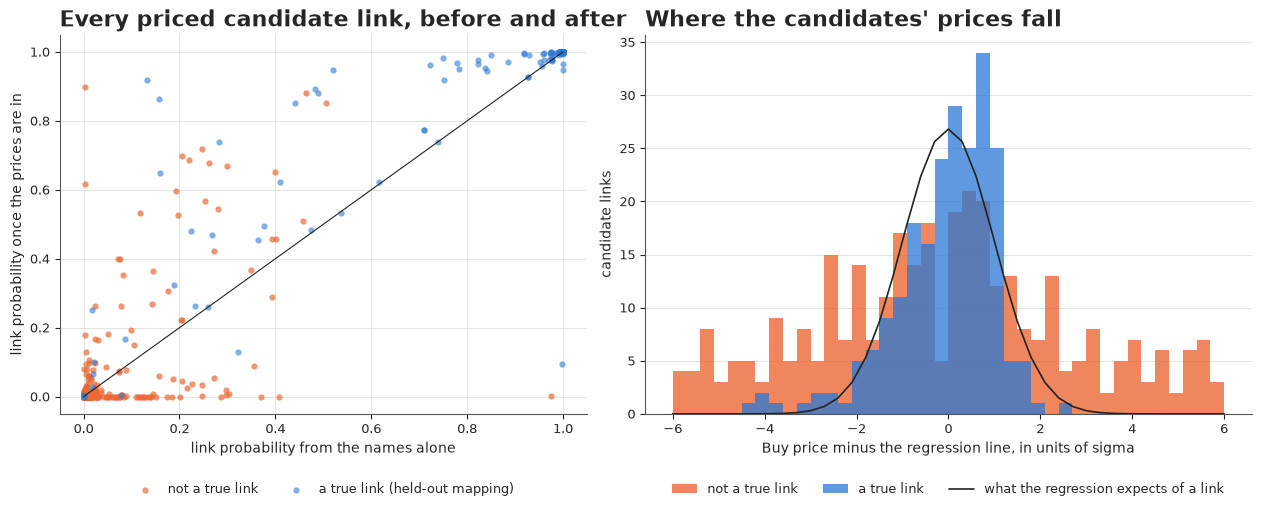

In [20]:
# the way back: what the prices do to the links (and a TEST of both versions against the held-out truth)
q_new = updated(OURS, x_c, y_c, q_c, q0_c)
truth_c = TRUTH[ia_c[:, None], jb_c] & (q_c > 0)
n_true_priced = int((TRUTH & PRICED).sum())
rows = {}
for label, qq in (("before the prices", q_c), ("after the prices", q_new)):
    sel = qq > 0.5
    rows[label] = {"links above 0.5": int(sel.sum()), "share true": truth_c[sel].mean(),
                   "true links found": truth_c[sel].sum() / n_true_priced, "expected links": qq.sum(),
                   "Brier score": ((qq - truth_c) ** 2).sum() / len(x_c)}
print(pd.DataFrame(rows).T.round(3).to_string())
moved = np.abs(q_new - q_c) > 0.3
up, down = moved & (q_new > q_c), moved & (q_new < q_c)
print(f"links whose probability moves by more than 0.3: {int(moved.sum())} ({int(up.sum())} up, {int(down.sum())} down); "
      f"of those moved up {truth_c[up].mean():.0%} are true, of those moved down {truth_c[down].mean():.0%}")
show = np.argsort(-np.abs(q_new - q_c).max(1))[:4]
for r in show:
    k = int(np.argmax(np.abs(q_new[r] - q_c[r])))
    print(f"   {abt['name'][ia_c[r]][:44]:<44} ${np.exp(x_c[r]):>7.2f} | "
          f"{buy['name'][jb_c[r, k]][:44]:<44} ${np.exp(y_c[r, k]):>7.2f} | "
          f"{q_c[r, k]:.2f} -> {q_new[r, k]:.2f} | {'true link' if truth_c[r, k] else 'not a link'}")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.0), gridspec_kw={"width_ratios": [1, 1.15]})
ax = axes[0]
has = q_c > 0
ax.plot([0, 1], [0, 1], color=INK, lw=0.8)
ax.scatter(q_c[has & ~truth_c], q_new[has & ~truth_c], s=20, color=ORANGE, alpha=0.7, lw=0, label="not a true link")
ax.scatter(q_c[has & truth_c], q_new[has & truth_c], s=20, color=BLUE, alpha=0.6, lw=0,
           label="a true link (held-out mapping)")
ax.set_xlabel("link probability from the names alone")
ax.set_ylabel("link probability once the prices are in")
ax.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
ax.set_title("Every priced candidate link, before and after", loc="left")
tidy(ax, grid="both")
ax = axes[1]
resid = (y_c - (OURS["a"].mean() + x_c + (OURS["b"].mean() - 1) * (x_c - X0))[:, None]) / OURS["sigma"].mean()
bins = np.linspace(-6, 6, 41)
near = np.abs(resid) < 6
ax.hist(resid[has & ~truth_c & near], bins=bins, color=ORANGE, alpha=0.8, label="not a true link")
ax.hist(resid[has & truth_c & near], bins=bins, color=BLUE, alpha=0.75, label="a true link")
ax.plot(bins, stats.norm.pdf(bins) * truth_c.sum() * (bins[1] - bins[0]), color=INK, lw=1.2,
        label="what the regression expects of a link")
ax.set_xlabel("Buy price minus the regression line, in units of sigma")
ax.set_ylabel("candidate links")
ax.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)
ax.set_title("Where the candidates' prices fall", loc="left")
tidy(ax)
print(f"candidate links further than 6 sigma from the line (not drawn): "
      f"{int((has & ~truth_c & ~near).sum())} that are not true links, {int((has & truth_c & ~near).sum())} that are")
sure = has & (q_new > 0.9)
print(f"links above 0.9 after the prices: {int(sure.sum())}; share of them more than two sigma from the line: "
      f"{np.mean(np.abs(resid[sure]) > 2):.1%} (a normal law expects 4.6%)")

The prices change the links, and the test says the change is a mixed blessing. More true links are found
(91% of the priced ones against 88%), but the links above 0.5 are less pure (93% true against 99%), and
the Brier score barely moves. Of the 23 links that the prices push up by more than 0.3, only 35% are
true.

The four examples show both sides. Two Canon ink cartridges had names that all but settled it (0.98);
one costs \$19 and the other \$41, and the price says no, rightly. A Sony camera case and a Canon camera
body were doubtful by name and are confirmed by price, rightly. And a phone case at \$34 in one shop and
\$10 in the other is a true link, which the regression refuses to believe (1.00 becomes 0.09).

The right panel explains why prices are weak evidence about links. The candidates that are not true
links are mostly siblings, and many of them sit within two sigma of the line, under the curve, where a
true link would be. A price can tell a cable from a television; it cannot tell one 46-inch set from the
next. And a normal error law has no room for a real product at a third of the price, so it explains such
a pair away as a false link, which is where the too-small $\sigma$ comes from.

So the way back repairs the regression and does not improve the linkage. We keep the regression of this
step, and for the links themselves we keep step 3.

> **The choice.** A regression whose likelihood sums over each listing's candidate partners, weighted by
> the link probabilities of step 3. *Rejected:* links above a threshold from pair-by-pair probabilities
> (slope 1.00 to 1.03 at thresholds from 0.3 up, where the truth is 1.05), and linkages sampled from the
> posterior and each taken as true (1.02, all 100 below the truth). *Considered:* links above 0.5 from
> step 3, taken as true, which give 1.04 here and are far simpler. We prefer the likelihood because it
> has no threshold to choose and because, as part 6 shows, it holds up when the links are worse. *What
> would change our mind:* price differences with heavier tails than a normal. The normal law is what
> lets a price veto a link, and it vetoed a real one. A Student-t would veto less, and correct less.

## 5 · How much cheaper is Buy?

The analyst asked for a discount, not a slope. The regression gives Buy's price relative to Abt's at any
price, with its uncertainty, and that uncertainty now includes the doubt about the links.

                                  analysis          at $20         at $100      at $1,000 P(b > 1) gap narrows by (points, $20 to $1,000)
                     true links (held out) -28% [-31, -24] -22% [-24, -19] -12% [-16, -7]    1.000                                     16
      sampled linkages, each taken as true -21% [-28, -13] -19% [-23, -14] -15% [-23, -7]    0.844                                      7
links kept uncertain inside the likelihood -26% [-29, -22] -20% [-23, -18] -12% [-17, -8]    1.000                                     13

priced Abt listings by their best link after the prices: above 0.9: 193, below 0.1: 46, in between (worth a human look): 41


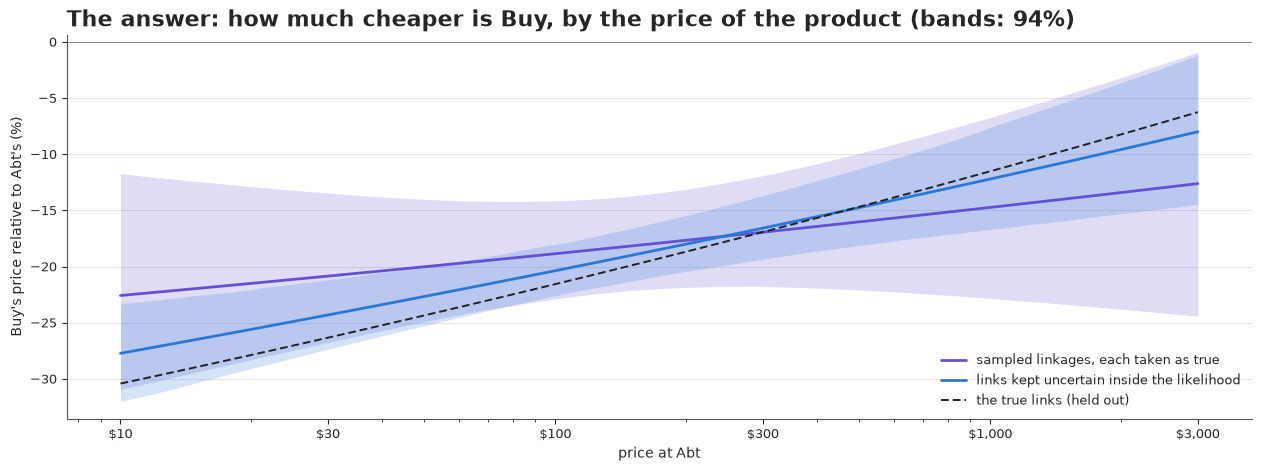

In [21]:
# The answer; the dashed line and the first row of the table are the TEST against the held-out truth
price_grid = np.exp(np.linspace(np.log(10), np.log(3000), 60))


def discount(d, price):
    lp = np.log(np.atleast_1d(price))[:, None]
    return np.exp(d["a"][None, :] + (d["b"][None, :] - 1) * (lp - X0)) - 1


fig, ax = plt.subplots(figsize=(12.5, 4.6))
for d, colour, label in ((SAMPLED, VIOLET, "sampled linkages, each taken as true"),
                         (OURS, BLUE, "links kept uncertain inside the likelihood")):
    curve = discount(d, price_grid) * 100
    ax.fill_between(price_grid, np.quantile(curve, 0.03, axis=1), np.quantile(curve, 0.97, axis=1), color=colour,
                    alpha=0.2, lw=0)
    ax.plot(price_grid, curve.mean(1), color=colour, lw=2, label=label)
ax.plot(price_grid, discount(ORACLE, price_grid).mean(1) * 100, color=INK, lw=1.4, ls=(0, (4, 2)),
        label="the true links (held out)")
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_xscale("log")
ax.set_xticks([10, 30, 100, 300, 1000, 3000], ["$10", "$30", "$100", "$300", "$1,000", "$3,000"])
ax.set_xlabel("price at Abt")
ax.set_ylabel("Buy's price relative to Abt's (%)")
ax.legend(frameon=False, fontsize=9, loc="lower right")
ax.set_title("The answer: how much cheaper is Buy, by the price of the product (bands: 94%)", loc="left")
tidy(ax)
answer = []
for label, d in (("true links (held out)", ORACLE), ("sampled linkages, each taken as true", SAMPLED),
                 ("links kept uncertain inside the likelihood", OURS)):
    at = discount(d, [20.0, 100.0, 1000.0]) * 100
    row = {"analysis": label}
    for k, p in enumerate((20, 100, 1000)):
        row[f"at ${p:,}"] = f"{at[k].mean():+.0f}% [{np.quantile(at[k], 0.03):+.0f}, {np.quantile(at[k], 0.97):+.0f}]"
    row["P(b > 1)"] = f"{(d['b'] > 1).mean():.3f}"
    row["gap narrows by (points, $20 to $1,000)"] = f"{(at[2] - at[0]).mean():.0f}"
    answer.append(row)
print(pd.DataFrame(answer).to_string(index=False))
best = q_new.max(1)
print(f"\npriced Abt listings by their best link after the prices: above 0.9: {int((best > 0.9).sum())}, "
      f"below 0.1: {int((best < 0.1).sum())}, "
      f"in between (worth a human look): {int(((best >= 0.1) & (best <= 0.9)).sum())}")

**The answer.** Buy is about 26% cheaper than Abt on a \$20 product, 20% cheaper at \$100 and 12%
cheaper at \$1,000, with 94% intervals of three to five points either side. The discount shrinks as
products get dearer, by about 13 points between \$20 and \$1,000, and the probability that it shrinks at
all is 1.000. The true links, which the analysis never saw, say 28%, 22% and 12%.

The analysis that sampled linkages and took each as true would have reported about a fifth off at every
price (21%, 19%, 15%) and a probability of 0.84 that the discount shrinks. Its answer for a \$100
product is nearly right. It is the pattern across prices that the false links erase.

For the links themselves the posterior gives a work list. Of the 280 priced Abt listings that have a
candidate, 193 have a best link above 0.9 and 46 have none above 0.1. The 41 in between are the ones
worth a person's time, the "possible links" of Fellegi and Sunter, which Sadinle (2017) formalises as a
linkage estimate that is allowed to abstain.

> **The choice.** The answer is the discount at three prices, with intervals that carry the doubt about
> the links, and a list of 41 listings for a person to check. *Rejected:* one average discount. It is
> the number that the linkage errors barely move (19% to 22% at \$100 across the three analyses), and it
> hides the pattern they erase. *Considered:* publishing a final list of links, those above 0.5 after
> the prices; that list is longer and less pure than step 3's, so step 3's probabilities stay the record
> of the links. *What would change our mind:* prices for the rest of the catalogue. Only 226 of the
> 1,097 true links are priced in both shops, and if the unpriced products differ, this is the discount
> on the priced ones.

## 6 · Which of our choices mattered?

Three choices in this notebook had rivals that a competent analyst might have taken. For the **classes**
of step 2: two classes with the match share capped, or two classes inside brand blocks. For the
**partners** of step 3: each pair decided alone. For the **links** in step 4: those above 0.5 taken as
true, or sampled linkages taken as true. That makes $3 \times 2 \times 3 = 18$ analysts. Each one
estimates the slope $b$. The figure is a specification curve (Simonsohn, Simmons and Nelson 2020, as in
E120): every analyst in order of the result, with the choices that define them underneath. Unlike in
E120 we can draw the truth across it.

In [22]:
# The 18 estimates use no truth; the grey band of the figure is the TEST against the held-out links
t0 = time.time()
FORKS = {  # choice: (what we did, the rejected options)
    "classes": ("three classes", "two classes, share capped", "two classes inside a brand"),
    "partners": ("one partner each", "each pair decided alone"),
    "links": ("uncertain, inside the likelihood", "above 0.5, taken as true", "sampled, taken as true"),
}
pair_prob = {0: P_PAIR, 1: idata_cap.posterior["p_match"].mean(("chain", "draw")).to_numpy()[PID]}
blk_p = np.zeros(len(pat))
blk_p[block["index"].to_numpy()] = idata_blk.posterior["p_match"].mean(("chain", "draw")).to_numpy()
pair_prob[2] = blk_p[PID]
Z_alt = {0: Z_3, 1: sample_linkages(pattern_weights(idata_cap), pair_prob[1], chains=2, draws=400),
         2: sample_linkages(pattern_weights(idata_blk, block), pair_prob[2], chains=2, draws=400)}
link_prob = {0: P_LINK, 1: link_probability(Z_alt[1]), 2: link_probability(Z_alt[2])}
gen = np.random.default_rng(RANDOM_SEED)
worlds, worst_f, div_f = [], 1.0, 0
for c_ in range(3):
    for p_ in range(2):
        P = link_prob[c_] if p_ == 0 else pair_prob[c_]
        for l_ in range(3):
            if l_ == 0 and p_ == 0:                           # one row per Abt listing, several candidates
                xr, yr, qr, q0r, _, _ = candidates(P, min_q=0.5 / (Z_alt[c_].shape[0] * Z_alt[c_].shape[1]))
                fits = [fit_prices(xr, yr, qr, q0r, seed=RANDOM_SEED)]
            elif l_ == 0:                                     # pairs are independent: one row per pair
                i, j = np.where((P > 0.01) & PRICED)
                pr = np.minimum(P[i, j], 1 - 1e-9)
                fits = [fit_prices(log_pa[i], log_pb[j][:, None], pr[:, None], 1 - pr, seed=RANDOM_SEED)]
            elif l_ == 1:
                fits = [fit_prices(*certain(P > 0.5), seed=RANDOM_SEED)]
            else:
                fits = []
                for s in range(30):
                    if p_ == 0:
                        zz = Z_alt[c_].reshape(-1, N_A)[gen.integers(Z_alt[c_].shape[0] * Z_alt[c_].shape[1])]
                        mask = np.zeros((N_A, N_B), bool)
                        mask[np.where(zz >= 0)[0], zz[zz >= 0]] = True
                    else:
                        mask = PRICED & (gen.random((N_A, N_B)) < P)
                    fits.append(fit_prices(*certain(mask), seed=s, draws=250, tune=300))
            worst_f = max(worst_f, max(worst_rhat(f) for f in fits))
            div_f += sum(int(f.sample_stats["diverging"].sum()) for f in fits)
            d = {v: np.concatenate([f.posterior[v].to_numpy().ravel() for f in fits]) for v in ("a", "b", "sigma")}
            gap = (discount(d, 1000.0) - discount(d, 20.0))[0] * 100
            worlds.append({"classes": c_, "partners": p_, "links": l_, "b": d["b"].mean(),
                           "lo": np.quantile(d["b"], 0.03), "hi": np.quantile(d["b"], 0.97),
                           "at100": (np.exp(d["a"]) - 1).mean() * 100, "narrowing": gap.mean(),
                           "sigma": d["sigma"].mean()})
worlds = pd.DataFrame(worlds)
worlds["rejected"] = (worlds[list(FORKS)] > 0).sum(axis=1)
DIAG.append({"fit": "18 analysts (regressions)", "divergences": div_f, "max r_hat": worst_f, "min ESS": np.nan})
print(f"18 analysts in {time.time() - t0:.0f} s; worst r_hat {worst_f:.3f}; divergences {div_f}")
table = worlds.assign(**{f: [FORKS[f][v] for v in worlds[f]] for f in FORKS}).drop(columns="rejected")
print(table.round(3).to_string(index=False))
truth_b = ORACLE["b"].mean()
effects = []
for f in FORKS:
    for v in range(1, len(FORKS[f])):
        one = worlds[(worlds["rejected"] == 1) & (worlds[f] == v)].iloc[0]
        effects.append({"choice": f, "rejected option": FORKS[f][v], "b, this choice alone": one["b"],
                        "mean b over all analysts who took it": worlds.loc[worlds[f] == v, "b"].mean(),
                        "furthest from the truth": worlds.loc[worlds[f] == v, "b"].sub(truth_b).abs().max()})
print(pd.DataFrame(effects).round(3).to_string(index=False))

18 analysts in 25 s; worst r_hat 1.016; divergences 0
                   classes                partners                            links     b    lo    hi   at100  narrowing  sigma
             three classes        one partner each uncertain, inside the likelihood 1.042 1.021 1.063 -20.367     13.382  0.219
             three classes        one partner each         above 0.5, taken as true 1.038 1.014 1.062 -20.130     12.083  0.242
             three classes        one partner each           sampled, taken as true 1.020 0.980 1.057 -18.875      6.234  0.353
             three classes each pair decided alone uncertain, inside the likelihood 1.040 1.018 1.062 -19.972     12.740  0.272
             three classes each pair decided alone         above 0.5, taken as true 1.021 0.986 1.056 -19.220      6.788  0.401
             three classes each pair decided alone           sampled, taken as true 0.958 0.892 1.016 -15.540    -13.830  0.585
 two classes, share capped        one partner each

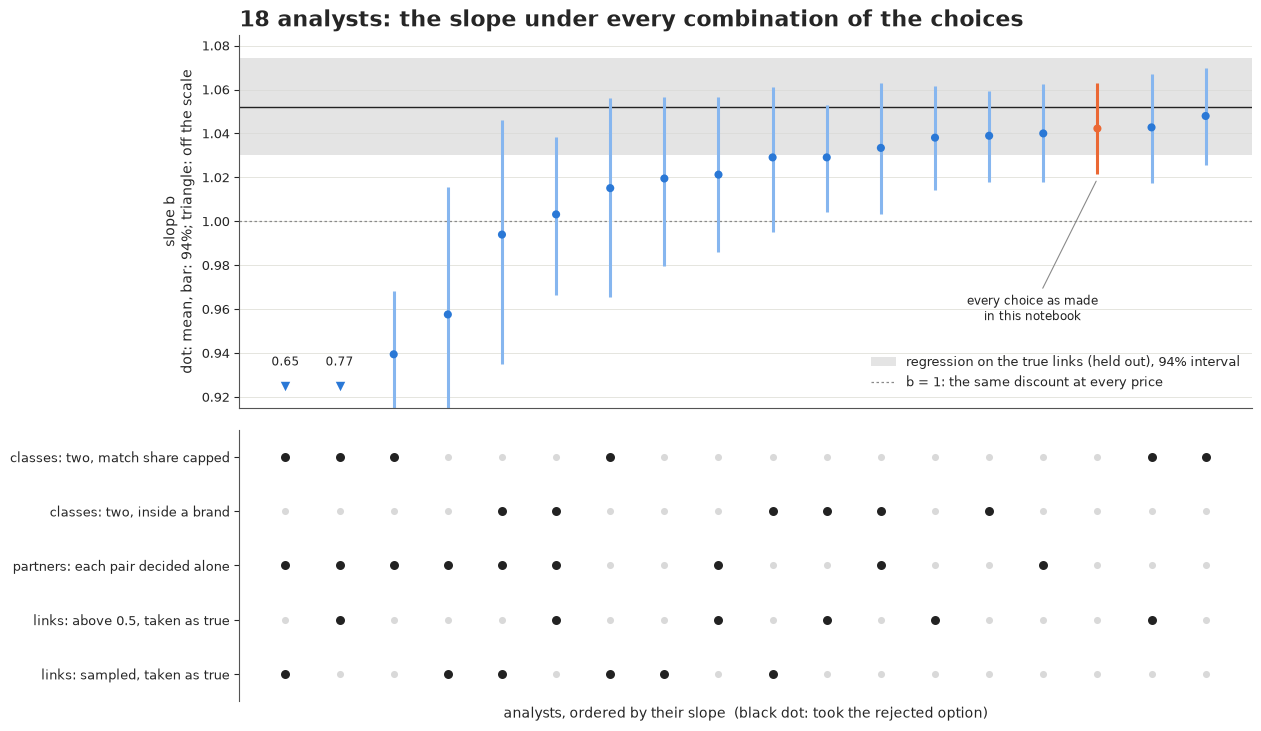

In [23]:
ws = worlds.sort_values("b").reset_index(drop=True)
fig, axes = plt.subplots(2, 1, figsize=(12.5, 7.2), sharex=True,
                         gridspec_kw={"height_ratios": [2.2, 1.6], "hspace": 0.06})
xw = np.arange(len(ws))
is_ours = (ws["rejected"] == 0).to_numpy()
FLOOR = 0.925
ax = axes[0]
ax.axhspan(*np.quantile(ORACLE["b"], [0.03, 0.97]), color=LIGHT, alpha=0.7, lw=0,
           label="regression on the true links (held out), 94% interval")
ax.axhline(truth_b, color=INK, lw=1.0)
ax.axhline(1.0, color=MUTED, lw=0.9, ls=(0, (2, 2)), label="b = 1: the same discount at every price")
inside = (ws["b"] > FLOOR).to_numpy()
ax.vlines(xw[inside], np.maximum(ws["lo"][inside], FLOOR - 0.01), ws["hi"][inside],
          color=np.where(is_ours, ORANGE, "#86b6ef")[inside], lw=2.2)
ax.scatter(xw[inside], ws["b"][inside], s=34, color=np.where(is_ours, ORANGE, BLUE)[inside], zorder=3, lw=0)
ax.scatter(xw[~inside], np.full((~inside).sum(), FLOOR), s=46, marker="v", color=BLUE, zorder=3, lw=0)
for xv, bv in zip(xw[~inside], ws["b"][~inside]):
    ax.text(xv, FLOOR + 0.008, f"{bv:.2f}", ha="center", va="bottom", fontsize=8.8, color=INK)
ax.annotate("every choice as made\nin this notebook", (xw[is_ours][0], ws["lo"][is_ours].iloc[0] - 0.002),
            (xw[is_ours][0] - 1.2, 0.955), fontsize=8.8, color=INK, ha="center",
            arrowprops={"arrowstyle": "-", "color": MUTED, "lw": 0.8})
ax.set_ylim(FLOOR - 0.01, 1.085)
ax.set_ylabel("slope b\ndot: mean, bar: 94%; triangle: off the scale")
ax.legend(frameon=False, fontsize=9, loc="lower right", bbox_to_anchor=(1.0, 0.02))
ax.set_title("18 analysts: the slope under every combination of the choices", loc="left")
tidy(ax)
ax = axes[1]
rows_ = [(f, v) for f in FORKS for v in range(1, len(FORKS[f]))]
labels = {("classes", 1): "classes: two, match share capped", ("classes", 2): "classes: two, inside a brand",
          ("partners", 1): "partners: each pair decided alone", ("links", 1): "links: above 0.5, taken as true",
          ("links", 2): "links: sampled, taken as true"}
for r_, (f, v) in enumerate(rows_):
    on = ws[f].to_numpy() == v
    ax.scatter(xw[~on], np.full((~on).sum(), r_), s=26, color=LIGHT, lw=0)
    ax.scatter(xw[on], np.full(on.sum(), r_), s=42, color=INK, lw=0)
ax.set_yticks(range(len(rows_)), [labels[r] for r in rows_])
ax.set_ylim(len(rows_) - 0.5, -0.5)
ax.set_xticks([])
ax.set_xlabel("analysts, ordered by their slope  (black dot: took the rejected option)")
ax.grid(False)
ax.spines[["top", "right", "bottom"]].set_visible(False);

Read the figure from the bottom: each column is an analyst, the black dots say which rejected options
that analyst took, and the top panel is the slope with its interval. The grey band is the regression on
the true links.

**Two analysts are off the scale**, at 0.65 and 0.77. Both took the capped two-class model, decided each
pair alone and took the resulting links as true. That model calls 7,900 pairs matches where 1,081 can
exist, so most of the links in their regressions are false. The third analyst of that family, who kept
the same bad links uncertain inside the likelihood, lands at 0.94. The likelihood rescues a great deal,
and not everything.

**One choice decides whether the others matter: one partner each.** All nine analysts who sampled
one-to-one linkages are between 1.01 and 1.05, whatever else they did. All six analysts below 1.01
decided each pair alone.

**The class model of part 2 mattered less than it seemed there.** With one partner each, the capped
two-class model, the one that failed its check by a factor of seven, gives slopes of 1.04 to 1.05 when
the links are thresholded or kept uncertain, as good as our three classes. The constraint does the work
of the third class: once a listing can have only one partner, the siblings have nowhere to go. We would
still choose three classes, because the check in part 2 needs no truth and the two-class model fails it.
But the afternoon spent on classes bought less than the constraint did.

**Within each of the six combinations of classes and partners, taking sampled linkages as true is the
worst way of using the links, or level with the worst.** Keeping the links uncertain inside the
likelihood is the best in all six, by a little where the links are good and by a lot where they are bad.

For the next linkage this suggests where to spend effort. Not on the mixture, where we spent most of
ours in pages, but on the structure the mixture ignores, one product and one partner, and on never
handing a later model a doubtful link as a fact.

## Summary

- **Linking is a chain, and the middle link carried the most.** A mixture on agreement patterns, a
  one-to-one matching, a regression. Every analyst who enforced one partner per listing got a slope
  between 1.01 and 1.05 where the truth is 1.05; every analyst below 1.01 decided pairs alone. *Limit:*
  one-to-one is an assumption, and the benchmark's mapping breaks it 21 times.
- **A two-class mixture found brands.** Fitted to all 1.18 million pairs it puts 18,700 pairs in its
  "match" class where 1,081 can exist; capping the share leaves 7,900 by posterior membership. Three
  classes (match, sibling, unrelated) reproduce the 39 pattern counts and imply about 1,830 matches.
  *Limit:* the size of the match class is the least certain number (1,570 to 2,530), and pair-by-pair
  probabilities stay badly calibrated: pairs given 0.9 to 0.98 are true 45% of the time.
- **One partner each turns opinions about pairs into a linkage.** 1,511 links above 0.5 with 59% true
  become 955 with 98% true, and the probabilities become usable. Gibbs updates alone left chains
  contradicting each other on 151 links; exchange and move steps fixed it. *Limit:* the weights are
  taken from the mixture and not re-estimated from the matching.
- **The suspicion we started with was half right.** Thresholded links bias the slope toward zero when
  the probabilities come from pairs decided alone (1.00 to 1.03 against 1.05). After the one-to-one step
  a threshold does no visible harm (1.04). The proposed cure, sampling linkages and taking each as true,
  is the biased one: 1.02, all 100 linkages below the truth, because each carries its 8% of false links
  into the regression as facts.
- **Doubt about a link belongs inside the likelihood.** A regression that sums over each listing's
  candidate partners gives 1.04 (1.02 to 1.06), and it was the best of the three ways of using links in
  every one of six comparisons. *Limit:* it disbelieves true links with unusual prices, and its $\sigma$
  is 0.22 where the true links have 0.24.
- **Prices are weak evidence about links.** Sending the regression's evidence back finds more true links
  (91% against 88%) and admits more false ones (93% true against 99%). Siblings cost about the same.
- **The answer.** Buy is about 26% cheaper than Abt at \$20, 20% at \$100 and 12% at \$1,000; the true
  links say 28%, 22% and 12%. 41 priced listings have a best link between 0.1 and 0.9 and are worth a
  human look.

## Try it yourself

1. **Heavier tails.** In `price_model`, replace the normal law of a true link by `pm.StudentT.dist(nu=4,
   mu=mu[:, None], sigma=sigma)`, and fit both the true links and the candidate rows. Does the phone
   case at \$34 against \$10 keep its link? How far do the slope of the true links and the slope with
   uncertain links each move, and does $\sigma$ still come out too small?
2. **The price as a comparison field.** Add a fourth entry to `LEVELS`: the absolute difference of the
   log prices cut at 0.1 and 0.35, and -1 where a price is missing. Refit the three classes, resample
   the linkages and redo the regression on the links above 0.5. In which direction should links chosen
   for their agreeing prices push the discount at \$100 and $\sigma$, and do they?
3. **Let the matching teach the classes.** `sample_linkages` takes its weights from step 2. Following
   Sadinle (2017), update them inside the sampler: after each pass, draw the match class's level
   probabilities from a Dirichlet with the counts of levels among the currently linked pairs (plus 2),
   and keep the non-match side fixed. Does the match class still claim 13% of "different" codes, and do
   the DVD players' links become any clearer?

In [24]:
print(pd.DataFrame(DIAG).round(3).to_string(index=False))
print(f"total run time: {time.time() - T_START:.0f} s")

                                                    fit  divergences  max r_hat  min ESS
                                            two classes            0      1.013  405.326
                              two classes, share capped            0      1.014  349.644
                                          three classes            0      1.005 1339.644
                             two classes inside a brand            0      1.006  583.638
                           regression on the true links            0      1.002 5858.437
regressions on thresholded and sampled links (122 fits)            0      1.036      NaN
                       regression with the links inside            0      1.004 5217.355
                              18 analysts (regressions)            0      1.016      NaN
total run time: 65 s
